# Adverserial attacks for class imbalance lending default datasets

In credit default predictions, financial institution work with highly class imbalanced datsets which require resampling in order to improve prediction of the positive class (default). The nature of the business case make the model susceptible to adverserial attacks because lenders with a high risk (predicted to default) will want to modify the features they have control in order to flip the prediction to either receive the lending or lower interest rate on the lending. A defence is to train the model with adversarial hardened examples but this is at the cost of accuracy, with this notebook we want to see if certain resampling models can adversarially 'harden' or 'weaken'models. This leads to the following research question central in this notebook:

**Research question:** Do resampling strategies harden or weaken class-imbalanced credit-risk models against adversarial attacks?

**Authors:** Tim Angevare · Rick Hezeman · Ruben Stevenaar · Roy Mulder


## What you will find in this notebook

This notebook follows the **CRISP-ML(Q)** methodology and is structured to reflect the phases of the machine learning lifecycle, from business and data understanding through data preparation, modeling, evaluation, and a reflection on deployment, monitoring, and limitations.

At a high level, the notebook covers:
- the business context and data understanding for the credit-risk classification problem,
- preparation of the LendingClub dataset, including feature pruning, encoding, and construction of five controlled imbalance levels,
- the modeling pipeline: four classifiers combined with five resampling strategies, including hyperparameter search and the KMeans-SMOTE clustering setup,
- the evaluation design: predictive performance, SHAP-based feature importance, fairness auditing via Disparate Impact Ratio, and constrained black-box adversarial attacks (PermuteAttack and ZOO),
- and a closing reflection on deployment considerations and study limitations.

## Table of Contents

0. [Executive Summary](#0-executive-summary)

[Methodology: CRISP-ML(Q)](#methodology-crisp-mlq)

1. [Business & Data Understanding](#1-business--data-understanding)  
   1.1 [Business Context & Problem Definition](#11-business-context--problem-definition)  
   1.2 [Data Source](#12-data-source)  
   1.3 [Initial Exploration](#13-initial-exploration)  

2. [Data Understanding & Quality](#2-data-understanding--quality)  
   2.1 [Feature Pruning](#21-feature-pruning)  
   2.2 [Final Feature Set](#22-final-feature-set)  
   2.3 [Target Definition](#23-target-definition)  
   2.4 [Exploratory Data Analysis](#24-exploratory-data-analysis)  

3. [Data Preparation](#3-data-preparation)  
   3.1 [Categorical Encoding](#31-categorical-encoding)  
   3.2 [Transformations & Missing Values](#32-transformations--missing-values)  
   3.3 [Constructing Imbalance Levels](#33-constructing-imbalance-levels)  

4. [Modeling](#4-modeling)  
   4.1 [Resampling Strategies](#41-resampling-strategies)  
   4.2 [Model Implementation](#42-model-implementation)  
   &nbsp;&nbsp;&nbsp;&nbsp;4.2.a [Data Understanding](#42a-data-understanding)  
   &nbsp;&nbsp;&nbsp;&nbsp;4.2.b [Training & Pipeline Infrastructure](#42b-training--pipeline-infrastructure)  
   &nbsp;&nbsp;&nbsp;&nbsp;4.2.c [Hyperparameter Search](#42c-hyperparameter-search)  
   &nbsp;&nbsp;&nbsp;&nbsp;4.2.d [Model Performance](#42d-model-performance)  
   4.3 [Neural Network Implementation](#43-neural-network-implementation)  

5. [Evaluation](#5-evaluation)  
   5.1 [Aggregate Model & Resampling Comparison](#51-aggregate-model--resampling-comparison)  
   5.2 [Global SHAP Analysis](#52-global-shap-analysis)  
   5.3 [Fairness: Disparate Impact Ratio](#53-fairness-disparate-impact-ratio)  

6. [Deployment & Monitoring](#6-deployment--monitoring)  

7. [Constrained Adversarial Attacks](#7-constrained-adversarial-attacks)  
   7.1 [Attack Setup](#71-attack-setup)  
   7.2 [PermuteAttack](#72-permuteattack)  
   7.3 [ZOO Attack](#73-zoo-attack)  

8. [Limitations & Reflection](#8-limitations--reflection)  

[Author Contributions](#author-contributions)  
[AI Statement](#ai-statement)



## 0. Executive Summary
 To be made

## Methodology: CRISP-ML(Q)

This project is structured using **CRISP-ML(Q)**, an extension of the traditional CRISP-DM framework adapted for machine learning projects. Where CRISP-DM centres on data mining and model development, CRISP-ML(Q) explicitly incorporates model quality assurance, deployment, and monitoring, which makes it well suited to a study where the end product is not only a trained classifier but also an evaluated claim about robustness and fairness under adversarial conditions.

CRISP-ML(Q) is used in this notebook to:
- link feature-engineering and resampling choices explicitly to the research question,
- justify modeling and hyperparameter decisions through documented design tables,
- evaluate models along three axes (predictive performance, fairness, adversarial robustness) rather than accuracy alone,
- and reflect on the limitations of treating a controlled, subsampled imbalance study as a stand-in for real-world class imbalance.

The CRISP-ML(Q) phases map onto this notebook as follows:

- **Business & Data Understanding** — defining the credit-risk and adversarial-robustness problem, and understanding the LendingClub dataset's structure, target definition, and natural class balance.
- **Data Preparation** — feature pruning, encoding, leakage removal, and construction of the five controlled imbalance levels used throughout the study.
- **Modeling** — implementation of the four classifiers, the five resampling strategies, the cross-validation and hyperparameter-search pipeline, and the neural network architecture.
- **Evaluation** — cross-validated predictive performance, SHAP feature-importance analysis, and a fairness audit via Disparate Impact Ratio across imbalance levels and resampling strategies.
- **Deployment & Monitoring** — a reflection on what operational deployment of such a model would require, including monitoring for the kind of feature-manipulation behaviour the adversarial attacks simulate.
- **Adversarial Robustness & Reflection** — the constrained black-box attack experiments (PermuteAttack, ZOO) that this study's research question is built around, followed by a discussion of limitations.

---

## 1. Data & Imports

This chapter sets up the computational environment and loads the data used throughout the notebook. It installs any missing packages, imports the numerical, plotting, statistical, machine-learning and deep-learning libraries relied on in later sections, fixes a global `RANDOM_STATE` for reproducibility, and reads in both the raw LendingClub dataset and result tables from the HPC clusters we used of the University of Twente (model scores, SHAP importances, fairness and adversarial-attack outputs) that the evaluation sections build on. Not everything in this notebook is runnable end-to-end locally: the model training, SHAP, fairness and adversarial-attack sections were executed on the HPC cluster, so their results are uploaded as CSV files and read back in here rather than recomputed.

*This work used the Dutch national e-infrastructure with the support of the SURF Cooperative using grant no. 2026.006.*

### 1.1. Optional package installation

Run this cell only if one or more required packages are missing or if you receive package version errors.  

To install the packages, remove the `#` in front of the command and run the cell once.  
After installation, restart the kernel and run the notebook again from the beginning.

In [ ]:
# %pip install numpy pandas matplotlib seaborn scipy scikit-learn imbalanced-learn xgboost shap torch torchvision skorch

  Using cached skorch-1.4.0-py3-none-any.whl.metadata (11 kB)
Using cached skorch-1.4.0-py3-none-any.whl (271 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### 1.2 Imports

Imports all packages used for data loading, preprocessing, resampling, modeling, evaluation, explainability, and adversarial attacks.

In [31]:
#  General utilities 
import os
import time
import locale
import warnings
warnings.filterwarnings("ignore")
from time import process_time

#  Numerical computing and data handling 
import numpy as np
import pandas as pd
import math

#  Plotting 
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.ticker as mticker

import matplotlib.patches as mpatches
import seaborn as sns

#  Statistics 
from scipy import stats
from scipy.spatial.distance import cdist
from scipy.stats import ks_2samp

#  Scikit-learn: preprocessing & utilities 
from sklearn.base import clone
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    StandardScaler,
)

#  Scikit-learn: models 
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

#  XGBoost 
from xgboost import XGBClassifier

#  Imbalanced-learn: resampling & metrics 
from imblearn.combine import SMOTEENN
from imblearn.metrics import geometric_mean_score
from imblearn.over_sampling import KMeansSMOTE, SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

#  Deep learning (PyTorch + skorch) 
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau
from skorch import NeuralNetClassifier
from skorch.callbacks import EarlyStopping, LRScheduler

#  Explainability 
import shap

#  Notebook display 
from IPython.display import display

#  Global random state 
RANDOM_STATE = 42

print("All packages imported successfully.")

All packages imported successfully.


### 1.3 Data & results imports

Two kinds of data are loaded here. The raw `accepted.csv` file is the full LendingClub accepted-loans dataset, which every preparation and modelling step operates on. The remaining CSVs under `outputs/` are results from the expensive runs. Therefore we ran it at the HPC clusters of the university. To be able to use it in evaluation, we uploaded the results — model scores, global SHAP importances, disparate-impact fairness rows, and adversarial-attack results.

*This work used the Dutch national e-infrastructure with the support of the SURF Cooperative using grant no. 2026.006.*

In [ ]:
# Raw dataset 
df = pd.read_csv("data/accepted.csv", low_memory=False)

# Cluster outputs 
model_results   = pd.read_csv("outputs/model_results.csv")
shap_wide       = pd.read_csv("outputs/shap_importances.csv")
fairness_rows   = pd.read_csv("outputs/dir_fairness_results.csv")
attack_results  = pd.read_csv("outputs/adversarial_attack_results.csv")

## 2. Business & Data Understanding

This phase establishes the business problem and the dataset that the rest of the study builds on. It explains why class imbalance and adversarial robustness matter together in a credit-risk context, identifies the data source, and performs an initial pass over the raw LendingClub data before any cleaning decisions are made.

### 2.1 Business Context & Problem Definition

Financial institutions that predict credit default work with highly class-imbalanced data, since most borrowers repay and only a minority default. Resampling methods are commonly used to improve a model's ability to detect that minority class. The business case is also adversarially sensitive: a borrower predicted to default — and therefore offered worse terms or denied credit — has a direct incentive to alter the features they control in order to flip that prediction. A common defence is to train on adversarially hardened examples, but this typically comes at the cost of predictive accuracy.

This notebook investigates whether resampling strategies chosen to address class imbalance also have a side effect on adversarial robustness — whether they incidentally harden or weaken the resulting model against this kind of feature manipulation.

### 2.2. Inital Exploration Dataset

This dataset's full feature set, loan status categories, and missingness are inspected before any cleaning decisions are made, so that later pruning choices (Section 2.1) can be justified against the data as it actually is.

In [ ]:
print(f"Number of Records: {df.shape[0]:,.0f}")
print(f"Number of Features: {df.shape[1]}")

Number of Records: 2,260,701
Number of Features: 151


The raw data contains 2,260,701 records across 151 features. Before deciding which loans to keep, the distribution of `loan_status` is inspected below.

In [ ]:
df.loan_status.value_counts()

loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
Name: count, dtype: int64

For this research we only care about paid off and defaulted a.k.a charged off

In [ ]:
df = df[df.loan_status.isin(['Fully Paid', 'Charged Off'])]

print("Columns:")
for col in df.columns:
    print(f" - {col}")

df.head()    

### 2.3. Feature selection

After filtering the data to a clean binary loan outcome, the dataset still contains many raw LendingClub columns. Not all of these columns are suitable for modeling. Some are mostly missing, some duplicate other variables, some contain almost no useful variation, and some would leak information that is only known after the loan outcome.

This section therefore applies **feature pruning**. This is different from model-driven feature selection. We are not asking which variables produce the highest performance. Instead, we clean the dataset into a fixed, understandable, and leakage-free set of input variables. The final result is a fixed set of 24 retained columns that is used throughout the rest of the notebook.

In [ ]:
MISSING_THRESHOLD = 0.10 
CORR_THRESHOLD = 0.80
NEAR_CONSTANT_THRESHOLD = 0.90
HIGH_CARDINALITY_COUNT = 10000

print(f"Starting features: {df.shape[1]}")

Starting features: 151


### 2.3.1. Checking missing values

We delete every feature which has more then 10% missing values to ensure

In [ ]:
missing_table = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_ratio": df.isnull().mean(),
}).sort_values("missing_ratio", ascending=False)

display(missing_table)

,missing_count,missing_ratio
member_id,2260701,1.000000
orig_projected_additional_accrued_interest,2252050,0.996173
hardship_reason,2249784,0.995171
hardship_payoff_balance_amount,2249784,0.995171
hardship_last_payment_amount,2249784,0.995171
...,...,...
total_rec_int,33,0.000015
disbursement_method,33,0.000015
hardship_flag,33,0.000015
debt_settlement_flag,33,0.000015


In [ ]:
# Drop columns with high higher then 10% missing values
cols_above_missing = missing_table[missing_table["missing_ratio"] > MISSING_THRESHOLD].index.tolist()

print(f"Columns dropped for missingness (> {MISSING_THRESHOLD:.0%}): {len(cols_above_missing)}")
for col in cols_above_missing:
    print(f" - {col}")

df = df.drop(columns=cols_above_missing)
print(f"\nRemaining features: {df.shape[1]}")

Columns dropped for missingness (> 10%): 59
 - member_id
 - orig_projected_additional_accrued_interest
 - hardship_reason
 - hardship_payoff_balance_amount
 - hardship_last_payment_amount
 - payment_plan_start_date
 - hardship_type
 - hardship_status
 - hardship_start_date
 - deferral_term
 - hardship_amount
 - hardship_dpd
 - hardship_loan_status
 - hardship_length
 - hardship_end_date
 - settlement_status
 - debt_settlement_flag_date
 - settlement_term
 - settlement_percentage
 - settlement_date
 - settlement_amount
 - sec_app_mths_since_last_major_derog
 - sec_app_revol_util
 - revol_bal_joint
 - sec_app_inq_last_6mths
 - sec_app_num_rev_accts
 - sec_app_open_acc
 - sec_app_earliest_cr_line
 - sec_app_fico_range_high
 - sec_app_mort_acc
 - sec_app_open_act_il
 - sec_app_fico_range_low
 - sec_app_collections_12_mths_ex_med
 - sec_app_chargeoff_within_12_mths
 - verification_status_joint
 - dti_joint
 - annual_inc_joint
 - desc
 - mths_since_last_record
 - mths_since_recent_bc_dlq
 - 

In [ ]:
X_candidates = df.copy()

print("Number of candidate features:", X_candidates.shape[1])
print(X_candidates.columns.tolist())

Number of candidate features: 92
['id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'policy_code', 'application_type', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'acc_open_past_24mths', 'avg_cur_bal', 'bc_open_to_buy', 'bc_util', 'chargeoff_within_12_mths', '

### 2.3.2. Checking correlation

Highly correlated features carry redundant information, which inflates variance in linear models and can distort feature-importance estimates. Here the absolute pairwise Pearson correlation is computed across all numeric candidate features, and every pair whose correlation exceeds the `CORR_THRESHOLD` (0.80) is listed so that one feature from each redundant pair can be removed in the following steps.

In [ ]:
numeric_candidates = X_candidates.select_dtypes(include=["int64", "float64", "bool"]).copy()

bool_cols = numeric_candidates.select_dtypes(include=["bool"]).columns
numeric_candidates[bool_cols] = numeric_candidates[bool_cols].astype(int)

corr_matrix = numeric_candidates.corr().abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={"level_0": "Feature 1", "level_1": "Feature 2", 0: "Correlation"})
    .sort_values("Correlation", ascending=False)
)

display(high_corr_pairs[high_corr_pairs["Correlation"] > CORR_THRESHOLD])


,Feature 1,Feature 2,Correlation
553,fico_range_low,fico_range_high,1.000000
1105,out_prncp,out_prncp_inv,0.999999
1,loan_amnt,funded_amnt,0.999755
1243,total_pymnt,total_pymnt_inv,0.999396
70,funded_amnt,funded_amnt_inv,0.999341
2,loan_amnt,funded_amnt_inv,0.999038
803,open_acc,num_sats,0.998966
3318,num_actv_rev_tl,num_rev_tl_bal_gt_0,0.983638
2240,tot_cur_bal,tot_hi_cred_lim,0.975582
1588,recoveries,collection_recovery_fee,0.970702


In [ ]:
# Create midpoint FICO score as its corrleation is exactly 1 with the original FICO range columns, and it is easier to interpret
df["fico_mid"] = (df["fico_range_low"] + df["fico_range_high"]) / 2

# Drop original FICO range columns after combining them
df = df.drop(columns=["fico_range_low", "fico_range_high"], errors="ignore")

In [ ]:
# For al the other highly correlated features, we will drop one of the pair. The following columns have been identified as highly correlated and will be dropped:
corr_drop_cols = [
    "out_prncp_inv", "total_pymnt_inv", "funded_amnt","funded_amnt_inv", "num_sats", 
    "num_rev_tl_bal_gt_0", "tot_hi_cred_lim","total_il_high_credit_limit","bc_util",
    "percent_bc_gt_75","bc_open_to_buy","total_bc_limit", "num_op_rev_tl", "avg_cur_bal",
    "last_fico_range_high","last_fico_range_low","num_bc_sats","num_actv_bc_tl",
    "total_rev_hi_lim", "num_bc_tl", "num_tl_30dpd",
]

existing_corr_drop_cols = [col for col in corr_drop_cols if col in df.columns]
df = df.drop(columns=existing_corr_drop_cols)

print(f"Removed {len(existing_corr_drop_cols)} highly correlated columns.")
print(f"Remaining features: {df.shape[1]}")

Removed 0 highly correlated columns.
Remaining features: 26


### 2.3.3. Checking for near constant columns

The next step removes variables that are unlikely to generalise. This includes columns where almost all rows have the same value, and categorical columns that behave like identifiers or free-text fields rather than meaningful borrower categories. remove if higher then 98% constant values

In [ ]:
near_constant_cols = []

for col in df.columns:
    top_freq = df[col].value_counts(normalize=True, dropna=False).iloc[0]
    if top_freq > NEAR_CONSTANT_THRESHOLD:
        near_constant_cols.append(col)

print("Low variance columns:", near_constant_cols)

df = df.drop(columns=near_constant_cols)
print(f"Removed {len(near_constant_cols)} low variance columns.")
print(f"Remaining features: {df.shape[1]}")

Low variance columns: []
Removed 0 low variance columns.
Remaining features: 26


### 2.3.4. Check for unique values in categorical columns

In [ ]:
# Check number of unique values in categorical columns

cat_cols = df.select_dtypes(include=["object"]).columns
cat_cardinality = (
    pd.DataFrame({
        "feature": cat_cols,
        "unique_values": [df[col].nunique(dropna=True) for col in cat_cols],
    })
    .sort_values("unique_values", ascending=False)
    .reset_index(drop=True)
)
display(cat_cardinality)

,feature,unique_values
0,id,2260701
1,url,2260668
2,emp_title,512694
3,title,63154
4,zip_code,956
5,earliest_cr_line,754
6,last_credit_pull_d,141
7,issue_d,139
8,last_pymnt_d,136
9,addr_state,51


In [ ]:
high_unique_cols = cat_cardinality[
    cat_cardinality["unique_values"] > 10_000
]["feature"].tolist()

print("Columns dropped because they have more than 10,000 unique values:")
print(high_unique_cols)

df = df.drop(columns=[col for col in high_unique_cols if col in df.columns])

print("Remaining columns:", df.shape[1])

Columns dropped because they have more than 10,000 unique values:
['id', 'url', 'emp_title', 'title']
Remaining columns: 52


In [ ]:
# Overview of remaining columns 
column_overview = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "missing_values": df.isna().sum().values,
    "missing_%": (df.isna().mean().values * 100).round(2),
    "unique_values": [df[col].nunique(dropna=True) for col in df.columns],
})

display(column_overview.sort_values("column").reset_index(drop=True))

print(f"Current number of columns: {df.shape[1]}")

,column,dtype,missing_values,missing_%,unique_values
0,acc_open_past_24mths,float64,50063,2.21,57
1,addr_state,str,33,0.00,51
2,annual_inc,float64,37,0.00,89368
3,delinq_2yrs,float64,62,0.00,37
4,dti,float64,1744,0.08,10845
5,earliest_cr_line,str,62,0.00,754
6,emp_length,str,146940,6.50,11
7,fico_mid,float64,33,0.00,48
8,grade,str,33,0.00,7
9,home_ownership,str,33,0.00,6


Current number of columns: 52


### 2.3.5. Last manual steps

Now we deleted features based on missing values, correlation, constantity, and unique values, we have 60 columns left. There we need to be sure that we ensure no data leakage and proxy so we have have fair estimations

In [ ]:
drop_for_leakage = [
    "out_prncp",
    "total_pymnt",
    "total_rec_prncp",
    "total_rec_int",
    "last_pymnt_d",
    "last_pymnt_amnt",
    "last_credit_pull_d"
    "issue_d"
]
drop_for_proxy_risk = [
    "int_rate",
    "grade",
    "sub_grade"
]

df = df.drop(columns=[col for col in drop_for_leakage if col in df.columns])
df = df.drop(columns=[col for col in drop_for_proxy_risk if col in df.columns])

Last features drop based on other kaggle sets and logisch nadenken.



In [ ]:
drop_for_generalisation = [
    # Too detailed location
    "zip_code",

    # Detailed collection/balance variables
    "tot_coll_amt",
    "tot_cur_bal",
    "total_bal_ex_mort",

    # Detailed credit-history timing variables
    "mo_sin_old_il_acct",
    "mo_sin_old_rev_tl_op",
    "mo_sin_rcnt_rev_tl_op",
    "mo_sin_rcnt_tl",
    "mths_since_recent_bc",

    # Detailed inquiry timing; overlaps with inq_last_6mths
    "mths_since_recent_inq",

    # Detailed account-count variables
    "num_accts_ever_120_pd",
    "num_actv_rev_tl",
    "num_bc_tl",
    "num_il_tl",
    "num_rev_accts",
    "num_tl_30dpd",
    "num_tl_op_past_12m",

    # Detailed delinquency percentage; overlaps with broader delinquency/FICO features
    "pct_tl_nvr_dlq"
]

df = df.drop(columns=[col for col in drop_for_generalisation if col in df.columns])

In [ ]:
print("Remaining features:", df.shape[1])
print(df.columns.tolist())

Remaining features: 25
['loan_amnt', 'term', 'installment', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'purpose', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'acc_open_past_24mths', 'mort_acc', 'pub_rec_bankruptcies', 'fico_mid']


We are now left with the following Features

| # | Feature | Description | Typical Datatype |
| --- | --- | --- | --- |
| 1 | `loan_amnt` | The listed amount of the loan applied for by the borrower. | `float64` |
| 2 | `term` | The number of payments on the loan (e.g., "36 months", "60 months"). | `object` / `int64` |
| 3 | `installment` | The monthly payment owed by the borrower if the loan originates. | `float64` |
| 4 | `emp_length` | Employment length in years (e.g., "10+ years", "< 1 year"). | `object` / `int64` |
| 5 | `home_ownership` | The home ownership status (e.g., RENT, OWN, MORTGAGE). | `object` / `category` |
| 6 | `annual_inc` | The self-reported annual income provided by the borrower. | `float64` |
| 7 | `verification_status` | Indicates if income or income source was verified by Lending Club. | `object` / `category` |
| 8 | `loan_status` | Current status of the loan (e.g., Fully Paid, Charged Off) — often the Target variable. | `object` / `category` |
| 9 | `purpose` | A category provided by the borrower for the loan request (e.g., debt_consolidation). | `object` / `category` |
| 10 | `addr_state` | The state provided by the borrower in the loan application. | `object` / `category` |
| 11 | `dti` | Debt-to-Income ratio (total monthly debt payments divided by self-reported monthly income). | `float64` |
| 12 | `delinq_2yrs` | The number of 30+ days past-due incidences of delinquency in the past 2 years. | `float64` |
| 13 | `earliest_cr_line` | The month the borrower's earliest reported credit line was opened. | `datetime64` / `object` |
| 14 | `inq_last_6mths` | The number of credit inquiries in the past 6 months. | `float64` |
| 15 | `open_acc` | The number of open credit lines in the borrower's credit file. | `float64` |
| 16 | `pub_rec` | Number of derogatory public records. | `float64` |
| 17 | `revol_bal` | Total credit revolving balance. | `float64` |
| 18 | `revol_util` | Revolving line utilization rate (amount of credit used relative to available credit). | `float64` |
| 19 | `total_acc` | The total number of credit lines currently in the borrower's credit file. | `float64` |
| 20 | `initial_list_status` | The initial listing status of the loan (W = whole, F = fractional). | `object` / `category` |
| 21 | `acc_open_past_24mths` | Number of trades/accounts opened in the past 24 months. | `float64` |
| 22 | `mort_acc` | Number of mortgage accounts. | `float64` |
| 23 | `pub_rec_bankruptcies` | Number of public record bankruptcies. | `float64` |
| 24 | `fico_mid` | Derived FICO score (usually the average of `fico_range_low` and `fico_range_high`). | `float64` |

We want to predict the rate of default so we wil rename it to target

## 2.4. Target Definition

`loan_status` is renamed to `target` and mapped to a binary outcome (1 = Charged Off / default, 0 = Fully Paid), which is the label used throughout the rest of the study.

In [ ]:
df = df.rename(columns={"loan_status": "target"})
df["target"] = df["target"].map({"Charged Off": 1, "Fully Paid": 0})

target_counts = df["target"].value_counts()
base_rate = df["target"].mean()

print("Target distribution:")
print(target_counts)
print(f"\nBase default rate: {base_rate:.1%}")

Target distribution:
target
0.0    1076751
1.0     268559
Name: count, dtype: int64

Base default rate: 20.0%


## 2.5 Exploratory Data Analysis

With the final feature set and target defined, the class balance and a small set of feature-target relationships are visualised to build intuition before encoding, resampling, and modeling decisions are made.

The default rate is broken down by loan purpose to see whether the reason for borrowing carries signal about repayment.

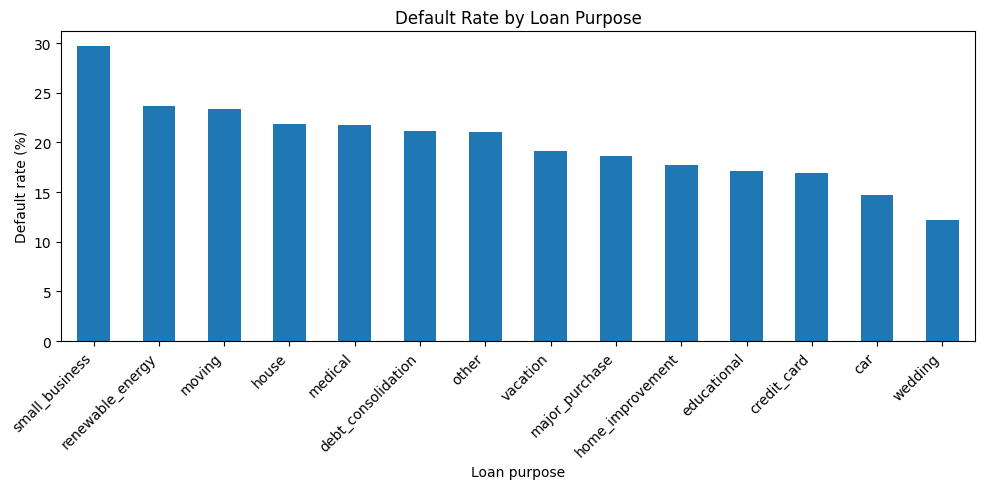

In [ ]:
purpose_default_rate = df.groupby("purpose")["target"].mean().sort_values(ascending=False) * 100

plt.figure(figsize=(10, 5))
purpose_default_rate.plot(kind="bar")
plt.title("Default Rate by Loan Purpose")
plt.xlabel("Loan purpose")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

A correlation heatmap of the numeric features checks for remaining redundancy and shows which features relate most strongly to the target.

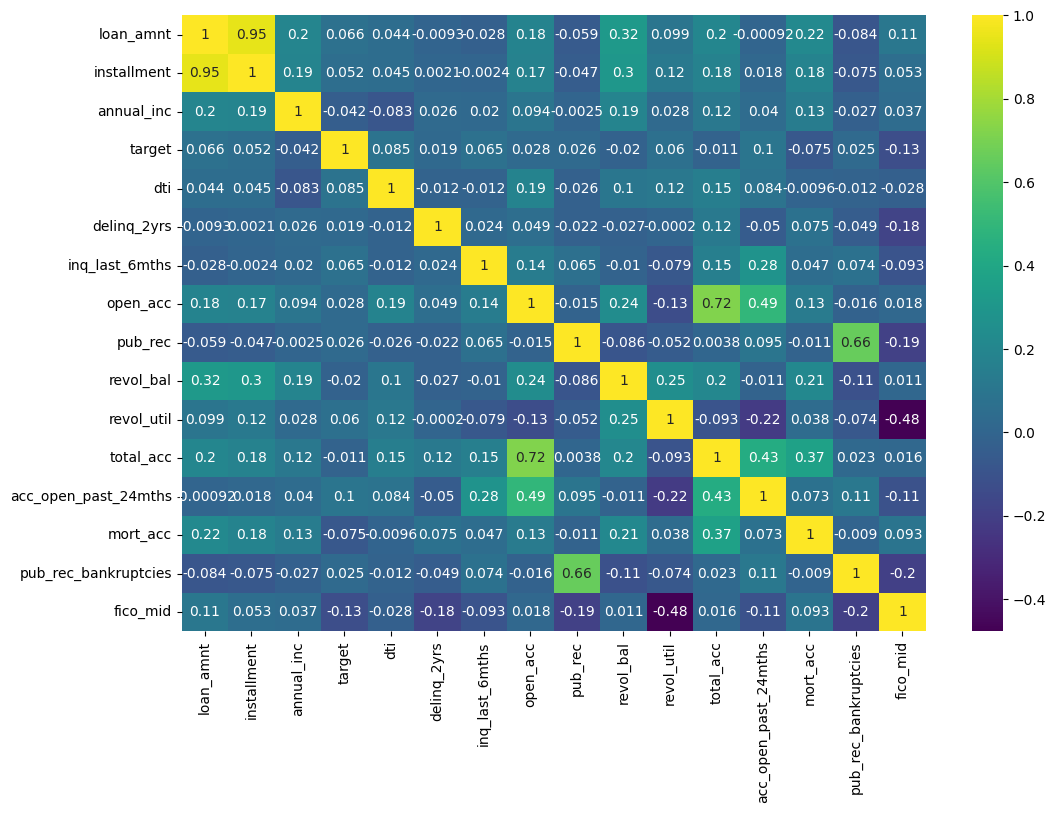

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="viridis")
plt.show()

Finally, the loan-amount and installment distributions are compared across the two classes, and each numeric feature's correlation with the target is ranked.

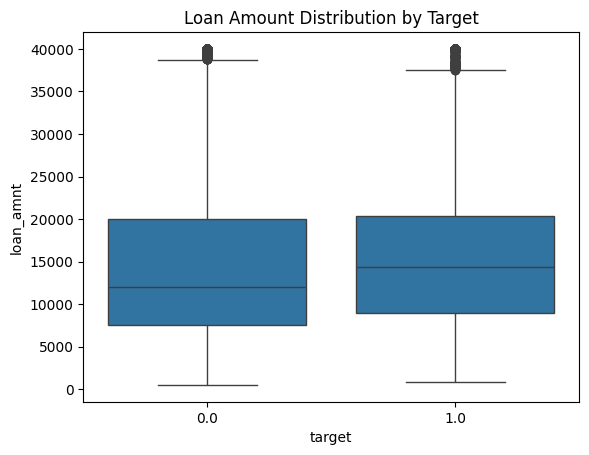

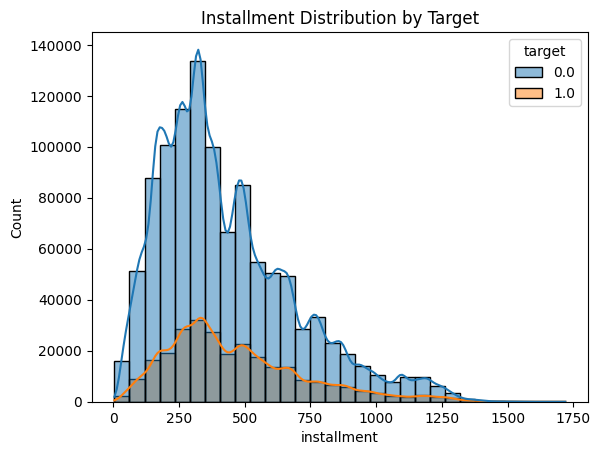

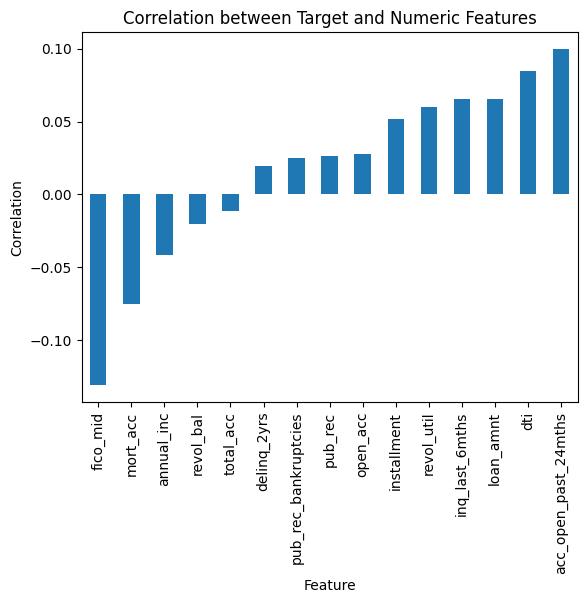

In [ ]:
boxplot = sns.boxplot(x="target", y="loan_amnt", data=df)
boxplot.set_title("Loan Amount Distribution by Target")
plt.show()

installment_plot = sns.histplot(data=df, x="installment", hue="target", kde=True, bins=30)
installment_plot.set_title("Installment Distribution by Target")
plt.show()

df.corr(numeric_only=True)["target"].drop("target").sort_values().plot(
    kind="bar",
    title="Correlation between Target and Numeric Features",
    ylabel="Correlation",
    xlabel="Feature",
)
plt.show()

In [ ]:
# Inspect skewness of numeric variables
numeric_features = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
numeric_features = [col for col in numeric_features if col != "target"]

# Exclude target-like or non-feature columns if still present
exclude_from_skew_check = ["loan_status"]
numeric_features = [col for col in numeric_features if col not in exclude_from_skew_check]

skew_summary = pd.DataFrame({
    "feature": numeric_features,
    "mean": [df[col].mean() for col in numeric_features],
    "median": [df[col].median() for col in numeric_features],
    "skewness": [df[col].skew() for col in numeric_features],
    "min": [df[col].min() for col in numeric_features],
    "max": [df[col].max() for col in numeric_features],
    "unique_values": [df[col].nunique(dropna=True) for col in numeric_features],
})

skew_summary = skew_summary.sort_values("skewness", ascending=False).reset_index(drop=True)

display(skew_summary)

,feature,mean,median,skewness,min,max,unique_values
0,annual_inc,77992.428687,65000.00,493.886088,0.00,1.100000e+08,89368
1,dti,18.824196,17.84,29.201854,-1.00,9.990000e+02,10845
2,revol_bal,16658.458078,11324.00,13.231988,0.00,2.904836e+06,102251
3,pub_rec,0.197528,0.00,11.376808,0.00,8.600000e+01,43
4,delinq_2yrs,0.306879,0.00,5.929811,0.00,5.800000e+01,37
5,pub_rec_bankruptcies,0.128194,0.00,3.371186,0.00,1.200000e+01,12
6,inq_last_6mths,0.576835,0.00,2.066187,0.00,3.300000e+01,28
7,mort_acc,1.555382,1.00,1.789684,0.00,9.400000e+01,47
8,acc_open_past_24mths,4.521656,4.00,1.402234,0.00,6.400000e+01,57
9,open_acc,11.612402,11.00,1.315545,0.00,1.010000e+02,91


# 3. Data Preparation

This phase converts the pruned dataset into a fully numeric, model-ready matrix and then constructs the five controlled imbalance levels that define the experimental grid. It covers categorical encoding, skew and missing-value handling, and the resampling logic used to build the 1%–20% minority datasets.

### 3.1 Categorical Encoding

Categorical features are encoded according to their structure: ordinal where a natural order exists, integer-parsed where a value is embedded in text, derived where a duration can be computed, and one-hot otherwise.

 After encoding, every feature is numeric: `emp_length` is mapped to 0–10 years, `term` is parsed to an integer number of months, and the remaining unordered categoricals (`home_ownership`, `purpose`, `verification_status`, `addr_state`, `initial_list_status`, `application_type`) are one-hot encoded with the first level dropped to avoid collinearity. `earliest_cr_line` remains as a datetime column, available for any downstream use that needs the raw date rather than a derived numeric feature. This produces the fully numeric design matrix required by the resampling and modeling pipeline.

`emp_length` has a natural order (years of employment), so it is ordinally encoded 0–10.

In [49]:
df["emp_length"] = df["emp_length"].map({
    "< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4,
    "5 years": 5, "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9, "10+ years": 10,
})

print("emp_length missing after ordinal encoding:", int(df["emp_length"].isna().sum()))

`term` embeds the number of months as text (e.g. "36 months"), so missing values are filled with the modal term first, then the text is stripped down to an integer month count.

In [ ]:
df["term"] = df["term"].fillna("36 months")
df["term"] = df["term"].str.strip().str.replace(" months", "").astype(int)

`earliest_cr_line` is a month-year string (e.g. "Aug-2003"); it is parsed to a proper date so that it can be handled consistently regardless of the notebook's system locale.

In [ ]:
locale.setlocale(locale.LC_TIME, 'C')  # ensure month abbreviations parse as English regardless of system locale
df["earliest_cr_line"] = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y")

# Derive a numeric feature: length of credit history in years, measured from the
# most recent origination date in the data (a fixed reference, so no per-row leakage).
reference_date = df["earliest_cr_line"].max()
df["credit_history_years"] = (
    (reference_date - df["earliest_cr_line"]).dt.days / 365.25
)

# The raw datetime column cannot be consumed by the numeric imputer/estimators
# downstream, so drop it once the numeric feature has been derived.
df = df.drop(columns=["earliest_cr_line"])

### 3.2 Transformations

`annual_inc` and `revol_bal` are heavily right-skewed monetary features, so both are log-transformed via `log1p`. The features requiring this transform are tracked in a single `LOG_FEATURES` set, since later sections (the adversarial attacks in Section 7) need to convert between the log-transformed model space and raw dollar values for the same columns.

In [ ]:
LOG_FEATURES = {"annual_inc", "revol_bal"}

for col in LOG_FEATURES:
    df[col] = np.log1p(df[col])

### 3.3. Missing values

 The remaining missing values are examined to decide between imputation and row removal. Imputation is deliberately deferred to the modeling pipeline (Section 4's `KNNImputer` step, applied per cross-validation fold) rather than being done here, so that no information from the full dataset leaks into any individual fold. The only cleanup performed at this stage is dropping rows that are missing so broadly that they carry essentially no usable signal.

In [ ]:
null_counts = df.isnull().sum()
print("Remaining missing values per column:")
print(null_counts[null_counts > 0])

rows_missing_loan_amnt = df[df["loan_amnt"].isnull()]
print(f"\nRows with loan_amnt missing: {len(rows_missing_loan_amnt)}")
print("Missing-value counts within those rows:")
print(rows_missing_loan_amnt.isnull().sum())

Remaining missing values per column:
loan_amnt                   33
installment                 33
emp_length              146940
home_ownership              33
annual_inc                  37
verification_status         33
issue_d                     33
target                  915391
purpose                     33
addr_state                  33
dti                       1744
delinq_2yrs                 62
earliest_cr_line            62
inq_last_6mths              63
open_acc                    62
pub_rec                     62
revol_bal                   33
revol_util                1835
total_acc                   62
initial_list_status         33
acc_open_past_24mths     50063
mort_acc                 50063
pub_rec_bankruptcies      1398
fico_mid                    33
dtype: int64

Rows with loan_amnt missing: 33
Missing-value counts within those rows:
loan_amnt               33
term                     0
installment             33
emp_length              33
home_ownership          3

The rows missing `loan_amnt` are missing nearly every other field as well, so they carry no usable signal and are dropped rather than imputed.

In [ ]:
df = df.dropna(subset=["loan_amnt"])

print("Missing values remaining after the drop:")
print(df.isnull().sum().sum())

Missing values remaining after the drop:
1167382


Finally, the remaining categorical columns are one-hot encoded, with the first level of each dropped to avoid collinearity in the design matrix.

In [ ]:
categorical_cols = df.select_dtypes(include="object").columns.tolist()
print("Columns one-hot encoded:", categorical_cols)

df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

Columns one-hot encoded: ['home_ownership', 'verification_status', 'issue_d', 'purpose', 'addr_state', 'initial_list_status']


### 3.3 Constructing Imbalance Levels

### This dataset does not have that much class imbalance (20%) compared to financial datasets. For our research we want class imbalance, so we will randomly undersample to get the minority class to 1%, 2%, 5%, 10% and 20%


A helper function, `calc_bias`, runs this Kolmogorov–Smirnov check for every numeric column between the full dataset and a given subsample.

In [ ]:
#Kolmogorov-Smirnov test per numeric column between the source data and a subsample
def calc_bias(source_df, sampled_df):
    results = {}
    for col in source_df.select_dtypes(include="number").columns:
        stat, p_value = ks_2samp(source_df[col], sampled_df[col])
        results[col] = (stat, p_value)
    return results

In [ ]:
datasets = {}
minority_fractions = [0.01, 0.02, 0.05, 0.1, 0.2]

majority = df[df["target"] == 0]
minority = df[df["target"] == 1]
natural_fraction = len(minority) / (len(minority) + len(majority))
print(f"Natural minority fraction: {natural_fraction:.3f}")

for frac in minority_fractions:
    if frac <= natural_fraction:
        n_minority = int(round(frac / (1 - frac) * len(majority)))
        majority_part = majority
        minority_part = minority.sample(n=n_minority, random_state=RANDOM_STATE)
    else:
        n_majority = int(round((1 - frac) / frac * len(minority)))
        majority_part = majority.sample(n=n_majority, random_state=RANDOM_STATE)
        minority_part = minority

    subsample = (
        pd.concat([majority_part, minority_part])
        .sample(frac=1, random_state=RANDOM_STATE)
        .reset_index(drop=True)
    )
    X = subsample.drop(columns="target")
    y = subsample["target"]
    datasets[frac] = (X, y)

    print(f"\nMinority fraction: {frac}")
    print(y.value_counts())
    print(y.value_counts(normalize=True))
    print("Bias statistics (Kolmogorov-Smirnov test):")
    print(calc_bias(df, subsample))

Natural minority fraction: 0.200

Minority fraction: 0.01
target
0.0    1076751
1.0      10876
Name: count, dtype: int64
target
0.0    0.99
1.0    0.01
Name: proportion, dtype: float64
Bias statistics (Kolmogorov-Smirnov test):
{'loan_amnt': (np.float64(0.039377000344166024), np.float64(0.0)), 'term': (np.float64(0.08229234478607517), np.float64(0.0)), 'installment': (np.float64(0.021488296265040452), np.float64(5.58501258065644e-295)), 'emp_length': (np.float64(nan), np.float64(nan)), 'annual_inc': (np.float64(nan), np.float64(nan)), 'target': (np.float64(nan), np.float64(nan)), 'dti': (np.float64(nan), np.float64(nan)), 'delinq_2yrs': (np.float64(nan), np.float64(nan)), 'inq_last_6mths': (np.float64(nan), np.float64(nan)), 'open_acc': (np.float64(nan), np.float64(nan)), 'pub_rec': (np.float64(nan), np.float64(nan)), 'revol_bal': (np.float64(0.007483885836361837), np.float64(3.752315947482764e-36)), 'revol_util': (np.float64(nan), np.float64(nan)), 'total_acc': (np.float64(nan), np.fl

In [ ]:
expected_final_columns = {
    "loan_amnt", "term", "installment", "emp_length", "annual_inc", "dti", "delinq_2yrs",
    "earliest_cr_line", "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util",
    "total_acc", "mort_acc", "pub_rec_bankruptcies", "fico_mid", "target",
}

# Verify base rate
base_rate_check = df["target"].mean()
assert abs(base_rate_check - 0.20) < 0.001, f"Base rate drifted: {base_rate_check:.4f}"

# Verify the non-one-hot-encoded numeric/derived columns are still present (one-hot dummy columns
# are excluded from this check by construction, since their exact names depend on category labels
# seen at encoding time)
missing_expected = expected_final_columns - set(df.columns)
assert not missing_expected, f"Missing expected columns: {missing_expected}"

# Verify imbalance levels
assert set(datasets.keys()) == {0.01, 0.02, 0.05, 0.1, 0.2}, f"Unexpected dataset keys: {set(datasets.keys())}"

# Verify shared downstream variables exist
for name, value in [
    ("LOG_FEATURES", LOG_FEATURES),
    ("RANDOM_STATE", RANDOM_STATE),
    ("calc_bias", calc_bias),
]:
    assert value is not None, f"{name} is not defined"

print("All verification checks passed:")
print(f" - Base default rate: {base_rate_check:.2%} (expected ~20.0%)")
print(f" - Final feature set contains all expected columns")
print(f" - datasets keys: {sorted(datasets.keys())}")
print(f" - LOG_FEATURES: {LOG_FEATURES}")
print(f" - RANDOM_STATE: {RANDOM_STATE}")
print(f" - calc_bias is defined: {callable(calc_bias)}")

All verification checks passed:
 - Base default rate: 19.96% (expected ~20.0%)
 - Final feature set contains all expected columns
 - datasets keys: [0.01, 0.02, 0.05, 0.1, 0.2]
 - LOG_FEATURES: {'annual_inc', 'revol_bal'}
 - RANDOM_STATE: 42
 - calc_bias is defined: True


,outlier_count,outlier_percentage
delinq_2yrs,421531,18.646303
pub_rec,357881,15.830763
pub_rec_bankruptcies,271920,12.028303
inq_last_6mths,94314,4.171953
open_acc,84754,3.749069
revol_bal,83785,3.706205
fico_mid,74846,3.310791
installment,66312,2.933292
acc_open_past_24mths,48076,2.126628
annual_inc,44562,1.971187


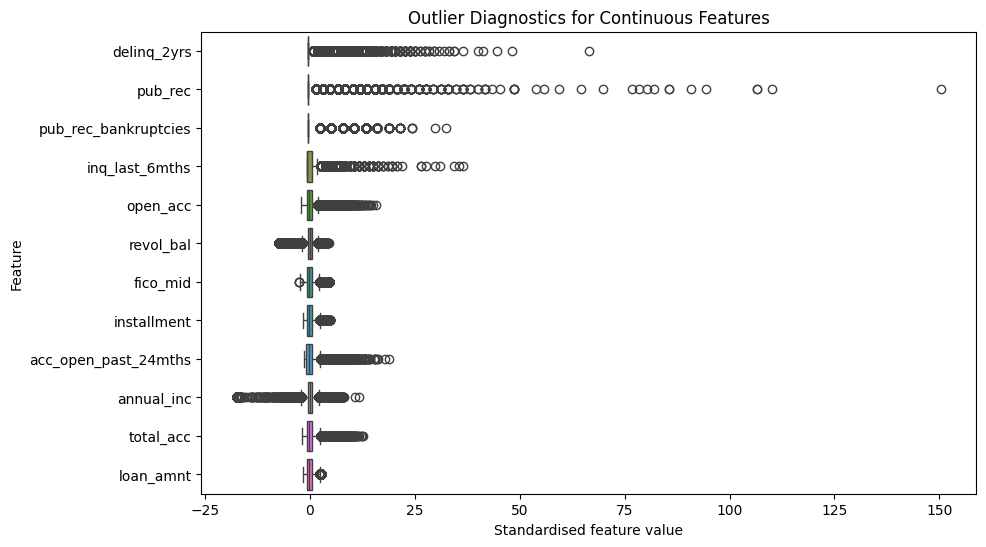

In [50]:
# Outlier diagnostics for continuous numerical features before scaling

continuous_cols = [
    col for col in df.select_dtypes(include=[np.number]).columns
    if col != "target" and df[col].nunique(dropna=True) > 2
]

Q1 = df[continuous_cols].quantile(0.25)
Q3 = df[continuous_cols].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (df[continuous_cols] < lower_bound) | (df[continuous_cols] > upper_bound)

outlier_summary = pd.DataFrame({
    "outlier_count": outlier_mask.sum(),
    "outlier_percentage": outlier_mask.mean() * 100
}).sort_values("outlier_percentage", ascending=False)

display(outlier_summary)

# Plot the features with the highest outlier percentages
top_outlier_cols = outlier_summary.head(12).index.tolist()

# Standardise only for visual comparison in the boxplot
df_boxplot = df[top_outlier_cols].copy()
df_boxplot = (df_boxplot - df_boxplot.mean()) / df_boxplot.std()

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_boxplot, orient="h")
plt.title("Outlier Diagnostics for Continuous Features")
plt.xlabel("Standardised feature value")
plt.ylabel("Feature")
plt.show()

# 4. Resampling

## 4.1 Theory

#### The Role of Resampling

Resampling modifies the **training distribution** so that the minority class receives a fairer learning signal. Critically:

> **Resampling is applied to the training partition only, inside each CV fold and never to the validation or test set. Therefore it is added to a pipeline instance passed into the crossfold validation function**

This prevents data leakage. In our pipeline:

```
Raw LendingClub → Feature Engineering → Set Imbalance Ratio
     → Stratified Split + 5-fold CV
         └── [RESAMPLE on train fold only]
             → Model Fit → Evaluate on val/test fold (no resampling)
```

A Kolmogorov-Smirnov bias check is run after resampling to confirm the resampled distribution is reasonable before evaluation proceeds.

---

### 4.1.2 The Five Resampling Strategies We Test

We compare **five strategies** spanning the main families of imbalance-handling approaches. The table below gives an overview before we drill into each:

| Strategy | Family | Data Changed? | Key Mechanism |
|---|---|---|---|
| **Baseline** | None | ✗ | Train on raw imbalanced data |
| **Class-Weight** | Cost-sensitive | ✗ | Penalise minority misclassifications in loss |
| **Random Under-Sampling (RUS)** | Under-sampling | ✓ (remove) | Randomly drop majority rows |
| **SMOTE-ENN** | Hybrid over+under | ✓ (add + remove) | Synthesise minority, then clean noisy points |
| **KMeans-SMOTE** | Over-sampling | ✓ (add) | Cluster-aware synthetic minority generation |

---

### 4.1.3 Strategy 1 — Baseline (No Resampling)

#### What it does

The model is trained on the raw, imbalanced dataset without any modification. Class proportions mirror the original data distribution (1%–20% minority, depending on the imbalance level set for that experiment run).

#### Why we include it

The baseline serves as the **experimental control**. Without it, we cannot quantify the effect of any resampling strategy. It also represents the naive default choice a practitioner might make if they simply run a classifier without addressing imbalance.

#### Expected behaviour

At low minority shares (1–2%), baseline models learn to predict the majority (negative) class almost exclusively. PR-AUC is near zero, and the adversarial Attack Success Rate (ASR) can vary substantially depending on the model architecture and the decision boundary shape that emerges from the skewed data.

---

### 4.1.4 Strategy 2 — Class-Weight (Cost-Sensitive Learning)

#### What it does

Class-weight does **not change the data at all**. Instead, it modifies the **loss function** so that misclassifying a minority-class instance (a defaulter) incurs a higher penalty than misclassifying a majority-class instance.

For a classifier with cross-entropy loss, the weighted loss is:

$$\mathcal{L}_{weighted} = -\sum_i \left[ w_1 \cdot y_i \log(\hat{p}_i) + w_0 \cdot (1 - y_i) \log(1 - \hat{p}_i) \right]$$

where $w_1 > w_0$ when the positive (default) class is the minority. The standard `class_weight='balanced'` setting in scikit-learn sets:

$$w_c = \frac{n_{samples}}{n_{classes} \cdot n_{samples_c}}$$

In our implementation, we pass `class_weight='balanced'` to `LogisticRegression`, `RandomForestClassifier`, pass `scale_pos_weight` to XGBoost and alter the criterion weights based on the imbalance ratio for the Neural Network.

#### Strengths

- **No information loss**: every original training observation is used.
- **No synthetic points**: avoids introducing artificial data that might distort the feature manifold.
- **Fast**: no resampling step adds to training time.

#### Weaknesses

- Does not help if the minority class is inherently hard to learn because it is embedded inside the majority region in feature space.
- Not directly applicable to all model types in the same way.

![Class-weight](./pictures/classweight.png)

---

### 4.1.5 Strategy 3 — Random Under-Sampling (RUS)

#### What it does

RUS randomly **removes majority-class instances** from the training set until the desired class ratio is reached (typically 1:1 or the target ratio).

```python
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)
X_resampled, y_resampled = rus.fit_resample(X_train, y_train)
```

#### Mechanism

Given a training set with $N_{maj}$ majority samples and $N_{min}$ minority samples, RUS randomly selects a subset $\tilde{N}_{maj} \leq N_{maj}$ without replacement, discarding the rest. The resulting dataset has $\tilde{N}_{maj} + N_{min}$ samples.

#### Strengths

- **Computationally trivial** — no interpolation or clustering needed.
- **Produces a compact, clean decision boundary** — the reduced majority class leaves more "room" for the minority, producing **simpler, harder-to-traverse** boundaries for an adversary.
- In our experiments, **RUS consistently yields the lowest Attack Success Rate (ASR)** across model types, making it the most robust strategy against adversarial perturbations.

#### Weaknesses

- **Information loss**: discarded majority instances may contain useful signal.
- At extreme imbalance (1% minority), RUS discards the vast majority of the dataset, which can hurt generalisation.

![RUS](./pictures/RUS.png)

---

### 4.1.6 Strategy 4 — SMOTE-ENN (Hybrid Over + Under Sampling)

#### What it does

SMOTE-ENN is a **two-stage hybrid** method that first over-samples the minority class using SMOTE, then cleans noisy instances from both classes using the Edited Nearest Neighbours (ENN) rule.

```python
from imblearn.combine import SMOTEENN

smote_enn = SMOTEENN(random_state=42)
X_resampled, y_resampled = smote_enn.fit_resample(X_train, y_train)
```

#### Stage 1 — SMOTE (Synthetic Minority Over-sampling TEchnique)

SMOTE was introduced by Chawla et al. (2002) and works as follows:

1. For each minority instance $x_i$, find its $k$ nearest neighbours in the minority class (default $k = 5$).
2. Randomly select one neighbour $x_{nn}$.
3. Generate a synthetic point along the line segment:

$$x_{new} = x_i + \lambda \cdot (x_{nn} - x_i), \quad \lambda \sim \text{Uniform}(0, 1)$$

This produces synthetic points that lie **on the line connecting two real minority instances**, interpolating within the minority feature manifold rather than extrapolating.

**Limitation of vanilla SMOTE**: it ignores the majority class entirely. Synthetic points can be placed in ambiguous regions that overlap with the majority, introducing noise into the decision boundary (He et al., 2008).

#### Stage 2 — ENN (Edited Nearest Neighbours)

After SMOTE, ENN applies a **cleaning step** (Wilson, 1972):

- For each instance (from both classes) in the resampled set, check its $k$ nearest neighbours.
- If the majority of those neighbours belong to a **different class**, remove that instance.

This removes points that are misclassified by their local neighbourhood — i.e., noisy or borderline examples — from both classes, producing a **cleaner decision boundary with reduced class overlap**.

#### Strengths

- Reduces overlap between classes that vanilla SMOTE ignores.
- Keeps the minority class better separated from the majority.

#### Weaknesses

- **Computationally expensive**: both SMOTE and ENN require nearest-neighbour searches.
- **Aggressive cleaning at high imbalance**: at 1–2% minority share, ENN can remove a large fraction of the newly generated synthetic minority points, potentially leaving the minority class even more underrepresented.
- In our experiments, SMOTE-ENN shows **poor PR-AUC at high imbalance**, likely because the aggressive cleaning removes too many minority points at extreme ratios.
- The jagged, complex boundaries produced by oversampling make SMOTE-ENN **more vulnerable to adversarial attacks** than RUS (higher ASR), especially for tree-based models.

![SMOTE-ENN](./pictures/SMOTE.png)

---

### 4.1.7 Strategy 5 — KMeans-SMOTE

#### What it does

KMeans-SMOTE (Douzas et al., 2018) addresses a key weakness of vanilla SMOTE: **it blindly synthesises in all minority regions, even near the majority class boundary**. KMeans-SMOTE adds a clustering step to restrict synthesis to "safe" minority clusters.

```python
from imblearn.over_sampling import KMeansSMOTE

km_smote = KMeansSMOTE(random_state=42, cluster_balance_threshold=0.1)
X_resampled, y_resampled = km_smote.fit_resample(X_train, y_train)
```

#### Mechanism

1. **K-Means clustering**: run K-Means on the entire dataset (both classes combined). Each cluster receives a label based on which class dominates it.
2. **Cluster filtering**: only clusters with a sufficiently high minority-class density (above `cluster_balance_threshold`) are selected for synthesis. This keeps synthetic points away from majority-dominated regions.
3. **SMOTE within clusters**: apply standard SMOTE interpolation *within* each selected minority-dense cluster.

The intuition is that synthesis is only safe within regions that are already "minority territory". Generating points near the majority boundary risks creating noisy synthetic instances that confuse the classifier.

#### Strengths

- Reduces class overlap compared to vanilla SMOTE by restricting synthesis to dense minority clusters.
- Cited to outperform SMOTE and several variants on benchmark datasets (Douzas et al., 2018; Alam et al., 2020).

#### Weaknesses

- **Sparse minority clusters at high imbalance**: at 1% minority share, the minority class may be too sparse to form reliable clusters. K-Means may fail to identify any valid minority cluster, or produce very few synthetic points, effectively falling back to vanilla SMOTE behaviour in borderline regions.
- **Computational cost**: K-Means over the full dataset adds significant overhead at large $N$.
- In our experiments, KMeans-SMOTE shows **high adversarial vulnerability** (ASR near 93–100% for RF and XGBoost combinations) and fairness issues: the Disparate Impact Ratio (DIR) for `annual_inc` drops to **0.78 at 1% imbalance** — below the 0.80 threshold that signals disparate impact — suggesting aggressive oversampling distorts the income distribution in the training data.

![KmeansSMOTE](./pictures/KMEANSMOTE.png)

---

## 8. Where Resampling Sits in Our Pipeline

A common methodological error is applying resampling **before the train/test split**, which causes data leakage: synthetic points derived from test-set neighbours end up influencing training, inflating performance metrics artificially (Blagus & Lusa, 2013; Kapelner & Bleich, 2016).

Our pipeline strictly avoids this:

```
Full LendingClub Dataset
        │
        ▼
 Feature Engineering
 (encoding)
        │
        ▼
 Set Imbalance Ratio
 (random undersample to target %)
        │
        ▼
 Stratified Train/Test Split  ←── Test set is never touched again
        │
        ▼
 5-Fold Stratified CV on Train
        │
        ├── [Fold k: Train partition]
        │         │
        │         ▼
        │   IMPUTE (fit on train only, predict on train and test)
        │         │
        │         ▼
        │   RESAMPLE (train partition only)
        │         │
        │         ▼
        │   Fit Model → Evaluate on Fold k Val partition
        │
        └── Repeat for all k folds → Average metrics
```

---

### 4.1.9 Summary Table: Resampling Method Properties

| Property | Baseline | Class-Weight | RUS | SMOTE-ENN | KMeans-SMOTE |
|---|---|---|---|---|---|
| Family | None | Cost-sensitive | Under-sampling | Hybrid | Over-sampling |
| Modifies data | ✗ | ✗ | ✓ | ✓ | ✓ |
| Introduces synthetic points | ✗ | ✗ | ✗ | ✓ | ✓ |
| Information loss | ✗ | ✗ | ✓ | Partial | ✗ |
| Computational cost | Low | Low | Low | High | High |
| PR-AUC (moderate imbalance) | Low | Medium | Medium | Medium-High | Medium |
| ASR robustness | Variable | Low | **Highest** | Low-Medium | Low |
| Fairness (DIR) risk | Low | Low | Low | Medium | **High at 1%** |


## 4.2 KMeansSMOTE

To use KMeansSMOTE we need to give an argument `n_cluster`. In order to find the optimal number of clusters we will use the elbow method.

In [ ]:
distortions = []
inertias = []
mapping1 = {}
mapping2 = {}

X = datasets[0.1][0]  # Using the dataset with 10% minority fraction for clustering
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

K = range(10, 100, 10)

for k in K:
    print(f"Calculating distortions and inertias for k={k}...")

    kmeansModel = KMeans(n_clusters=k, random_state=RANDOM_STATE).fit(X_imputed)  # Using the dataset with 10% minority fraction for clustering
    distortions.append(sum(np.min(cdist(X_imputed, kmeansModel.cluster_centers_, 'euclidean'), axis=1)**2) / X_imputed.shape[0])

    inertias.append(kmeansModel.inertia_)

    print(f"Distortion for k={k}: {distortions[-1]}")
    print(f"Inertia for k={k}: {inertias[-1]}")

    mapping1[k] = distortions[-1]
    mapping2[k] = inertias[-1]

Calculating distortions and inertias for k=10...


c:\Users\tim_a\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\tim_a\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\tim_a\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\tim_a\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\tim_a\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

Distortion for k=10: 858183.3385991938
Inertia for k=10: 1026721964466.6458
Calculating distortions and inertias for k=20...
Distortion for k=20: 190098.3150229616
Inertia for k=20: 227431723110.31964
Calculating distortions and inertias for k=30...
Distortion for k=30: 67076.8541643949
Inertia for k=30: 80250077553.73734
Calculating distortions and inertias for k=40...
Distortion for k=40: 40539.58549994179
Inertia for k=40: 48501154696.27716
Calculating distortions and inertias for k=50...
Distortion for k=50: 24830.786591878692
Inertia for k=50: 29707304770.655857
Calculating distortions and inertias for k=60...
Distortion for k=60: 17346.138288310758
Inertia for k=60: 20752746386.752586
Calculating distortions and inertias for k=70...
Distortion for k=70: 14340.27881620199
Inertia for k=70: 17156566172.91633
Calculating distortions and inertias for k=80...
Distortion for k=80: 11583.711111565099
Inertia for k=80: 13858636136.764364
Calculating distortions and inertias for k=90...
D

Distortion values:
10 : 858183.3385991938
20 : 190098.3150229616
30 : 67076.8541643949
40 : 40539.58549994179
50 : 24830.786591878692
60 : 17346.138288310758
70 : 14340.27881620199
80 : 11583.711111565099
90 : 10215.22971702599


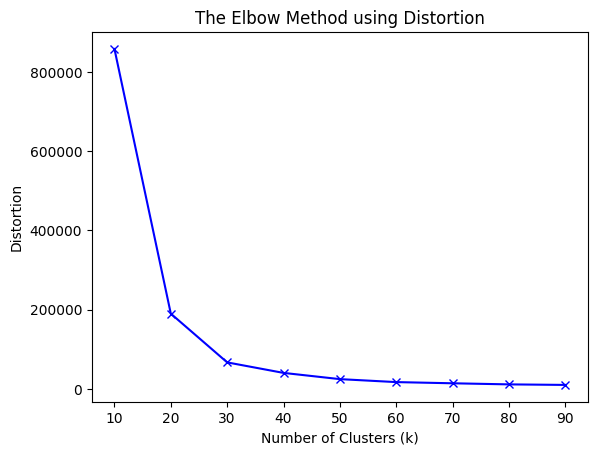

In [ ]:
print("Distortion values:")
for key, val in mapping1.items():
    print(f'{key} : {val}')

plt.plot(K, distortions, 'bx-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Distortion')
plt.title('The Elbow Method using Distortion')
plt.show()

Inertia values:
10 : 1026721964466.6458
20 : 227431723110.31964
30 : 80250077553.73734
40 : 48501154696.27716
50 : 29707304770.655857
60 : 20752746386.752586
70 : 17156566172.91633
80 : 13858636136.764364
90 : 12221398681.151876


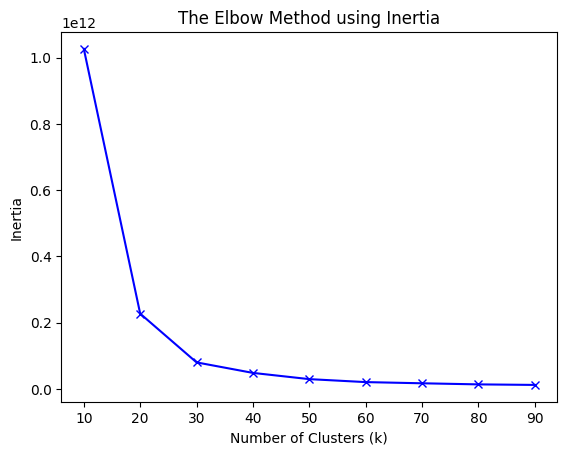

In [ ]:
print("Inertia values:")
for key, val in mapping2.items():
    print(f'{key} : {val}')

plt.plot(K, inertias, 'bx-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('The Elbow Method using Inertia')
plt.show()

Looking at the figures we see the elbow at 30 so we assign our variable to that value

In [ ]:
NUM_CLUSTERS = 30  # Chosen based on the elbow method results

## 4.3 Define

We declare a dictionary in order to define our sampling methods

In [ ]:
samplers = {
    "Baseline": None,   
    "RandomUnderSampler": RandomUnderSampler(sampling_strategy="majority", random_state=RANDOM_STATE),
    "SMOTEENN":           SMOTEENN(sampling_strategy="minority", random_state=RANDOM_STATE, n_jobs=-1),
    "KMeansSMOTE": KMeansSMOTE(
        sampling_strategy="minority",
        random_state=RANDOM_STATE,
        cluster_balance_threshold=0.01,
        kmeans_estimator=MiniBatchKMeans(n_clusters=NUM_CLUSTERS, random_state=RANDOM_STATE, n_init=3),
        n_jobs=-1,
    ),
    "ClassWeight":        None,
}

## 4.4 Define 5Kfold

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 5. Model Implementation

## 5.1 Model Selection

Based on our literature review, we select four classifiers that jointly span the interpretability–performance trade-off and represent the model families most commonly benchmarked in imbalanced credit-risk classification tasks:

- **Logistic Regression** — the baseline and most explainable model in the set. Coefficients map directly onto feature-level risk contributions, which is why logistic regression remains the standard for regulated credit scoring. We do **not** expect it to be the top performer on discriminative metrics. The literature shows tree-based ensembles usually outperform it on AUC/F1 (e.g. Ginting et al., 2025) but it serves as our interpretability anchor and a proxy for what a bank could realistically deploy under regulatory constraints such as the EU AI act.

- **Random Forest** — a bagged ensemble of decision trees, included as a mid-complexity, variance-reducing model. It has repeatedly shown strong, stable performance on imbalanced classification tasks and offers a useful contrast point for how bagging (RF) vs. boosting (XGBoost) respond to adversarial perturbation and resampling.

- **XGBoost** — our black-box tree-based model. Gradient-boosted trees are consistently reported as top or near-top performers in credit-risk and imbalanced classification benchmarks throughout the literature, which makes XGBoost a natural high-performance counterpart to logistic regression's interpretability.

- **Neural Network** — included to represent the fully black-box, non-tree-based family, and because deep learning approaches to imbalanced credit/fraud classification are an active and growing research area. Neural networks also have a substantially larger and more mature adversarial robustness literature than tree ensembles. Adversarial examples were first characterized in this setting with CNNs in image classification which lets us draw on established attack methods more directly than we can for tree-based models, where adversarial robustness research is comparatively recent and less standardized.

**Why this set, specifically:** the four models let us cross two axes relevant to our research question: model family (linear vs. tree vs. neural) and transparency (white-box vs. black-box) while keeping the design tractable at 4 classifiers × 5 resampling strategies × 5 imbalance ratios. Framing logistic regression as the "explainability baseline" rather than a performance benchmark is also more defensible given the literature.

First we start by defining some helper functions

In [ ]:
results = []

def best_f1_threshold(y_true, y_proba):
    precision, recall, thresholds = precision_recall_curve(y_true, y_proba)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return thresholds[np.argmax(f1[:-1])]

#Helper for NN models that expect float32 input
def to_float32(X):
    return np.asarray(X, dtype=np.float32)

We want to define our pipeline to pass into the 5kfold. We add the imputer for NaN values and scale the values

We intially wanted to use `KNNImputer` as this would impute more acurate values, but due to the extra computational overhead we decided to replace it with `SimpleImputer`

In [ ]:
def build_pipeline(estimator, sampler):
    steps = [
        #("imputer", KNNImputer(n_neighbors=5, weights="distance")),
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", StandardScaler()),
    ]
    if sampler is not None:
        steps.append(("sampler", sampler))
    if estimator.__class__.__name__ == "NeuralNetClassifier":
        steps.append(("to_float32", FunctionTransformer(to_float32)))
    steps.append(("clf", estimator))
    return ImbPipeline(steps)

## 5.2 Explainability: SHAP Analysis Across Resampling Methods

### What are Shapley values?

Shapley values originate in cooperative game theory (Shapley, 1953), where they answer a specific question: if a group of players cooperate to produce some total payoff, how should that payoff be fairly split among them, given that players contribute different amounts depending on who else is in the coalition? The Shapley value for player *i* is the average marginal contribution of *i* across every possible ordering (coalition) of players:

$$\phi_i(f) = \sum_{S \subseteq N \setminus \{i\}} \frac{|S|!\,(|N|-|S|-1)!}{|N|!} \big(f(S \cup \{i\}) - f(S)\big)$$

It is the *only* attribution method satisfying a specific set of fairness axioms (efficiency, symmetry, dummy, additivity) simultaneously which is why it's treated as a principled, rather than ad hoc, way to split credit (Shapley, 1953; as formalized for ML in Lundberg & Lee, 2017).

### From game theory to feature attribution: SHAP

SHAP (SHapley Additive exPlanations) repurposes this idea for ML: features take the place of "players," and the "payoff" is the model's prediction. For a given prediction, SHAP asks how much each feature contributed relative to a baseline (typically the model's average output), by averaging that feature's marginal effect across all possible subsets of the other features being present or absent. The magnitude of a Shapley value reflects how a feature influences the prediction, while its sign indicates the direction of that influence.  Lundberg & Lee (2017) showed SHAP unifies several earlier attribution methods (e.g. LIME) under one framework with two useful guarantees: additivity — the feature attributions sum to the model's output, so contributions aggregate consistently even across categorical variables — and local accuracy/consistency, meaning a feature's attributed impact can't shrink if its actual impact on the prediction grows. 

Naively, computing exact Shapley values requires evaluating a model on every possible feature subset — exponential in the number of features. For tree-based models specifically (our RF and XGBoost), **TreeExplainer** exploits tree structure to compute exact SHAP values in polynomial time and additionally captures feature interactions, which is why it's the standard choice for tree ensembles rather than the slower model-agnostic KernelExplainer  (Lundberg et al., 2020). For logistic regression we can use the (closed-form, cheap) LinearExplainer, and for the neural network, a sampling-based or gradient-based explainer (e.g. DeepExplainer/GradientExplainer).

### Why we're computing this

We want to compute SHAP values for each model under each resampling condition to test whether resampling changes *what the model learns to rely on*, not just how well it performs. SHAP lets us check, feature-by-feature, whether a resampling method is inflating reliance on a proxy-sensitive feature relative to the untreated baseline, rather than only observing the downstream fairness metric. Concretely, for each (classifier × resampling method × imbalance ratio) combination we will:

1. Fit the model on the resampled training data.
2. Compute SHAP values on a **held-out, natively-distributed** evaluation set (not the resampled training set — resampling changes the population SHAP is evaluated over, which would confound "importance changed" with "evaluation distribution changed").
3. Compare global feature importance rankings (mean |SHAP value| per feature) across resampling methods, using a rank-correlation measure (e.g. Kendall's τ) rather than eyeballing bar charts, so shifts can be reported quantitatively.
4. Treat any ranking shift as a *hypothesis* rather than a settled finding, given the fidelity-distortion issue above — ideally cross-check at least one surprising shift against a simpler diagnostic (e.g. permutation importance) before writing it up as a substantive result.

### References
- Shapley, L. S. (1953). A value for n-person games. *Contributions to the Theory of Games*, 2(28), 307–317.
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems 30 (NeurIPS 2017)*.
- Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., ... & Lee, S.-I. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence*, 2(1), 56–67.
- [2026 preprint] How Class Imbalance Treatments Distort SHAP Attribution Fidelity: A Monte Carlo Investigation of Ranking and Magnitude Errors. *Research Square*. (Preprint — not yet peer-reviewed; verify before final citation.)

In [ ]:
shap_records = [] 

N_SHAP_MAX   = 200   # test samples for TreeExplainer / LinearExplainer
N_SHAP_NN    = 20    # test samples for NeuralNet (KernelExplainer is slow)
N_SHAP_NN_BG = 50    # background samples for KernelExplainer

In [ ]:
def preprocess_for_shap(pipe, X):
    # Remove resampler steps from the pipeline, as they are not used at inference time and may not support transform().
    X_t = X
    for _, step in pipe.steps[:-1]:
        if hasattr(step, "fit_resample"): 
            continue
        X_t = step.transform(X_t)
    return np.asarray(X_t)


def get_sv_class1(sv):
    # Normalise SHAP output to shape (n_samples, n_features) for the positive class.
    if isinstance(sv, list) and len(sv) == 2:
        return sv[1]
    if hasattr(sv, "values"):               # shap.Explanation object (SHAP >= 0.41)
        v = sv.values
        return v[:, :, 1] if v.ndim == 3 else v
    if isinstance(sv, np.ndarray) and sv.ndim == 3:
        return sv[:, :, 1]
    return sv


def compute_shap_for_fold(pipe, train_idx, test_idx, X, model_name, sampler_name, imbalance_ratio):
    rng = np.random.default_rng(RANDOM_STATE)
    clf  = pipe.named_steps["clf"]
    feat = list(X.columns)

    try:
        if model_name in ("XGBClassifier", "RandomForestClassifier"):
            X_te = preprocess_for_shap(pipe, X.iloc[test_idx])
            idx  = rng.choice(len(X_te), min(N_SHAP_MAX, len(X_te)), replace=False)
            sv   = get_sv_class1(shap.TreeExplainer(clf).shap_values(X_te[idx]))

        elif model_name == "LogisticRegression":
            X_tr = preprocess_for_shap(pipe, X.iloc[train_idx])
            X_te = preprocess_for_shap(pipe, X.iloc[test_idx])
            idx  = rng.choice(len(X_te), min(N_SHAP_MAX, len(X_te)), replace=False)
            sv   = get_sv_class1(shap.LinearExplainer(clf, X_tr).shap_values(X_te[idx]))

        elif model_name == "NeuralNetClassifier":
            X_te_raw = X.iloc[test_idx].astype(np.float32)
            X_tr_raw = X.iloc[train_idx].astype(np.float32)
            ei = rng.choice(len(X_te_raw), min(N_SHAP_NN,    len(X_te_raw)),  replace=False)
            bi = rng.choice(len(X_tr_raw), min(N_SHAP_NN_BG, len(X_tr_raw)), replace=False)

            def nn_predict(X_raw):
                df = pd.DataFrame(X_raw, columns=feat).astype(np.float32)
                return pipe.predict_proba(df)[:, 1]

            sv = shap.KernelExplainer(nn_predict, X_tr_raw.iloc[bi]).shap_values(
                X_te_raw.iloc[ei], nsamples=100, l1_reg="num_features(10)"
            )
        else:
            return

        shap_records.append({
            "Model":           model_name,
            "Sampler":         sampler_name,
            "Imbalance ratio": imbalance_ratio,
            "importances":     pd.Series(np.abs(sv).mean(axis=0), index=feat),
        })

    except Exception as e:
        print(f"  SHAP skipped for {model_name}+{sampler_name} (IR={imbalance_ratio}): {e}")

## 5.3 Scoring Function and Evaluation Metrics

### Methodology

`score_model` takes the fold-level outputs of the stratified k-fold cross-validation run performed in `model_kfold` (`cv_out`) and turns them into a single row of comparable metrics for one (classifier, resampling method, imbalance ratio) combination, plus a confusion matrix plot and a SHAP explanation.

Two of the metrics namely ROC-AUC and PR-AUC (`average_precision`) come straight from the CV scorers and are **threshold-free**: they summarize how well the model ranks positives above negatives across all possible thresholds, so they don't depend on any decision cutoff (see the CV section above).

### Metrics reported

- **ROC-AUC (mean)** — threshold-independent; the probability that a randomly chosen positive case is scored above a randomly chosen negative case. Taken from the CV scorer, so it reflects ranking quality across all folds, independent of our threshold choice.
- **PR-AUC (mean)**, labeled `average_precision` — also threshold-independent, but the area under the precision-recall curve rather than the ROC curve. In our case it is more informative than ROC-AUC under class imbalance, since it doesn't dilute false positives against a large negative class.
- **F1 (mean)** — macro-averaged F1 (harmonic mean of precision and recall, averaged across both classes) computed per fold at that fold's optimal threshold, then averaged across folds. Macro-averaging prevents the majority (non-default) class from dominating the score.
- **Precision (mean) / Recall (mean)** — macro-averaged, computed once on the pooled OOF predictions (not fold-averaged like F1). Reported separately from F1 because two models can share an F1 score while trading off precision and recall very differently which matters here since false negatives (missed defaults) and false positives (rejected good borrowers) carry different real-world costs.
- **G-Mean (mean)** — the geometric mean of sensitivity and specificity, $G=\sqrt{TPR \times TNR}$, computed on the pooled OOF predictions. Introduced specifically for imbalanced learning; it penalizes a classifier that scores well on the majority class while failing the minority class in a way accuracy.
- **Threshold (mean)** — the average of the per-fold F1-optimal thresholds, reported so a reader can see how far the operating point has moved from the naive 0.5 default.
- **Confusion matrix / TP, FP, TN, FN** — computed on the pooled OOF predictions and displayed normalized by true class (`normalize='true'`) so each row shows that class's recall directly; the same values are stored as raw entries in the results table.
- **Train F1 (mean) / F1 gap (train − test)** — the gap between training-fold and test-fold F1 is a simple overfitting diagnostic. It's particularly relevant when comparing resampling methods, since synthetic oversampling (e.g. SMOTE variants) can make a model fit its (synthetic) training distribution much better than it generalizes to real, untouched test data.
- **Fit time / Score time** — per-fold wall-clock cost, useful for comparing practicality across the full 4×5×5 factorial design rather than for judging predictive quality.

In [ ]:
def score_model(imbalance_ratio, cv_out, estimator, sampler_name, X, y, normalize='true'):
    y_arr = np.asarray(y)
    y_pred = np.empty_like(y_arr)
    fold_thresholds, train_f1s, test_f1s = [], [], []
    for est, train_idx, test_idx in zip(
        cv_out["estimator"], cv_out["indices"]["train"], cv_out["indices"]["test"]
    ):
        proba_train = est.predict_proba(X.iloc[train_idx])[:, 1]
        thr = best_f1_threshold(y_arr[train_idx], proba_train)
        proba_test = est.predict_proba(X.iloc[test_idx])[:, 1]
        y_pred[test_idx] = (proba_test >= thr).astype(y_arr.dtype)
        fold_thresholds.append(float(thr))
        train_f1s.append(f1_score(y_arr[train_idx], (proba_train >= thr).astype(y_arr.dtype), average="macro"))
        test_f1s.append(f1_score(y_arr[test_idx], y_pred[test_idx], average="macro"))

    cm = confusion_matrix(y_arr, y_pred, normalize=normalize)
    disp = ConfusionMatrixDisplay(cm, display_labels=np.unique(y_arr))
    disp.plot(cmap="Blues", values_format=".2f" if normalize else "d")
    plt.title(f"{estimator.__class__.__name__} + {sampler_name} + imbalance ratio {imbalance_ratio} ({skf.get_n_splits()}-fold OOF)")
    plt.show()

    train_f1 = float(np.mean(train_f1s))
    test_f1 = float(np.mean(test_f1s))

    results.append({
        "Model": estimator.__class__.__name__,
        "Sampler": sampler_name,
        "Imbalance ratio": imbalance_ratio,
        "fit time (s)": round(cv_out["fit_time"].mean(), 2),
        "Score time (s)": round(cv_out["score_time"].mean(), 2),
        "Threshold (mean)": round(float(np.mean(fold_thresholds)), 4),
        "F1 (mean)":        test_f1,
        "ROC-AUC (mean)":   cv_out["test_roc_auc"].mean(),
        "PR-AUC (mean)":    cv_out["test_average_precision"].mean(),
        "Recall (mean)":    recall_score(y_arr, y_pred, average="macro"),
        "Precision (mean)": precision_score(y_arr, y_pred, average="macro"),
        "G-Mean (mean)":    geometric_mean_score(y_arr, y_pred),
        "Train F1 (mean)":  train_f1,
        "F1 gap (train-test)": round(train_f1 - test_f1, 3),
        "TP": cm[1, 1] if normalize else int(cm[1, 1]),
        "FP": cm[0, 1] if normalize else int(cm[0, 1]),
        "TN": cm[0, 0] if normalize else int(cm[0, 0]),
        "FN": cm[1, 0] if normalize else int(cm[1, 0])
    })
    
    compute_shap_for_fold(
        cv_out["estimator"][-1],
        cv_out["indices"]["train"][-1],
        cv_out["indices"]["test"][-1],
        X,
        estimator.__class__.__name__,
        sampler_name,
        imbalance_ratio,
    )

## 5.4 Define Kfold and Gridsearch

Finally we define our Kfold function where we score based on ROC AUC and PR AUC 

In [ ]:

def model_kfold(sampler_name, estimator, X, y, imbalance_ratio=None):
    print(f"Training {estimator.__class__.__name__} + {sampler_name} with imbalance ratio {imbalance_ratio}...")

    print("Performing cross-validation...")
    time_start = process_time()

    sampler = samplers[sampler_name]

    pipe = build_pipeline(estimator, sampler)

    cv_out = cross_validate(
        pipe, X, y, cv=skf,
        scoring=("roc_auc", "average_precision"),
        return_train_score=True,
        return_estimator=True,
        return_indices=True,
        # CV folds run serially: the model (RF n_jobs=-1 / XGB) and sampler
        # already parallelise internally, so parallelising folds here too would
        # oversubscribe the CPU. Set n_jobs=-1 only if the estimator is single-threaded.
        n_jobs=1,
    )

    print(f"Done in {round(process_time() - time_start, 2)} seconds.")

    score_model(imbalance_ratio, cv_out, estimator, sampler_name, X, y)

Applying class weight is different per model so we have to define a function to compute this correctly

In [ ]:
def apply_class_weight(estimator, sampler_name, y):
    name = estimator.__class__.__name__
    y_arr = np.asarray(y)
    if sampler_name == "ClassWeight":
        if name in ("LogisticRegression", "RandomForestClassifier"):
            estimator.set_params(class_weight="balanced")
        elif name == "XGBClassifier":
            estimator.set_params(scale_pos_weight=(y_arr == 0).sum() / (y_arr == 1).sum())
        elif name == "NeuralNetClassifier":
            _, counts = np.unique(y_arr, return_counts=True)
            w = torch.tensor(counts.sum() / (2 * counts), dtype=torch.float32)
            estimator.set_params(criterion__weight=w)
    else:
        if name in ("LogisticRegression", "RandomForestClassifier"):
            estimator.set_params(class_weight=None)
        elif name == "XGBClassifier":
            estimator.set_params(scale_pos_weight=1.0)
        elif name == "NeuralNetClassifier":
            estimator.set_params(criterion__weight=None)
    return estimator

Now we implement our loops. First over all sampling methods, then over all imbalance ratios per model

In [ ]:
def loop_samplers(estimator, X, y, imbalance_ratio):
    for sampler_name, sampler in samplers.items(): 
        model_kfold(sampler_name, apply_class_weight(estimator, sampler_name, y), X, y, imbalance_ratio=imbalance_ratio)

In [ ]:
def loop_imbalance_ratios(estimator):
    for frac, dataset in datasets.items():
        print(f"=== Minority fraction: {frac} ===")
        X, y = dataset
        if estimator.__class__.__name__ == "NeuralNetClassifier":
            X = X.astype(np.float32)
            y = y.to_numpy().astype(np.int64)
            
        loop_samplers(estimator, X, y, imbalance_ratio=frac)

Before training on the various imbalance ratios we will first use gridsearch to find the optimal params for the models

In [ ]:

config = {}


In [ ]:

def find_best_hyperparameters(estimator, X, y, param_distributions):
    param_distributions["clf__random_state"] = [RANDOM_STATE]

    pipe = ImbPipeline([
        #("imputer", KNNImputer(n_neighbors=5, weights="distance")),
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", StandardScaler()),
        ("clf", estimator)
    ])

    search = GridSearchCV(
        pipe,
        param_distributions,
        scoring="average_precision",
        refit=True,
        n_jobs=-1
    )

    search.fit(X, y)

    print("Best hyperparameters:")
    print(search.best_params_)

    print(f"Score with best hyperparameters: {search.best_score_:.4f}")

    config[estimator.__class__.__name__] = {k.removeprefix("clf__"): v for k, v in search.best_params_.items()}

In [ ]:
weight = (datasets[0.2][1] == 0).sum() / (datasets[0.2][1] == 1).sum()

## 5.5 Implement models

### 5.5.1 XGBoost

In [ ]:

param_distributions_xgb = {
    "clf__n_estimators":     [400, 800],
    "clf__max_depth":        [4, 6],
    "clf__learning_rate":    [0.05, 0.1],
    "clf__min_child_weight": [1, 10],
    "clf__reg_lambda":       [1, 5],
    "clf__subsample":        [0.8],
    "clf__colsample_bytree": [0.8],
}


find_best_hyperparameters(XGBClassifier(), datasets[0.2][0], datasets[0.2][1], param_distributions_xgb)

In [ ]:
loop_imbalance_ratios(XGBClassifier(**config["XGBClassifier"]))

### 5.5.2 Logistic Regression

In [ ]:
param_distributions_logistic= {
    "clf__C": [0.01, 0.1, 1, 10],
    "clf__penalty": ["l1", "l2"],
    "clf__solver": ["saga"],
    "clf__max_iter": [2000],
}

find_best_hyperparameters(LogisticRegression(), datasets[0.2][0], datasets[0.2][1], param_distributions_logistic)

In [ ]:
loop_imbalance_ratios(LogisticRegression(**config["LogisticRegression"]))

### 5.5.3 Random Forest

In [ ]:
param_distributions_random_forest = {
    "clf__n_estimators":     [500],
    "clf__max_depth":        [None, 16, 24],
    "clf__min_samples_leaf": [1, 5, 20],     
    "clf__max_features":     ["sqrt", 0.3],
} 

find_best_hyperparameters(RandomForestClassifier(), datasets[0.2][0], datasets[0.2][1], param_distributions_random_forest)

In [ ]:
loop_imbalance_ratios(RandomForestClassifier(**config["RandomForestClassifier"], n_jobs=-1))

## 5.6 Implement Neural Network

## Neural Network Architecture

### Structure

`NeuralNetwork` is a small fully-connected feedforward network (multilayer perceptron) with two hidden layers:

| Layer | Operation | Output shape |
|---|---|---|
| Input | — | `(batch, input_dim)` |
| `layer_1` | Linear(`input_dim` → 64) | `(batch, 64)` |
| `activation_1` | ReLU | `(batch, 64)` |
| `dropout_1` | Dropout(p=0.2) | `(batch, 64)` |
| `layer_2` | Linear(64 → 64) | `(batch, 64)` |
| `activation_2` | ReLU | `(batch, 64)` |
| `dropout_2` | Dropout(p=0.2) | `(batch, 64)` |
| `layer_3` (output) | Linear(64 → 2) | `(batch, 2)` |

`input_dim` is set dynamically from the data (`n_features = next(iter(datasets.values()))[0].shape[1]`) rather than hardcoded, so the same class can be instantiated for datasets with different feature counts — relevant here since different resampling methods or preprocessing steps could in principle change the number of columns going in.


## 5.6.1 Define our neural network architecture

In [ ]:
class NeuralNetwork(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.layer_1 = nn.Linear(input_dim, 64)
        self.activation_1 = nn.ReLU()
        self.dropout_1 = nn.Dropout(0.2)
        self.layer_2 = nn.Linear(64, 64)
        self.activation_2 = nn.ReLU()
        self.dropout_2 = nn.Dropout(0.2)
        self.layer_3 = nn.Linear(64, 2)

    def forward(self, X):

        X = self.layer_1(X)
        X = self.activation_1(X)
        X = self.dropout_1(X)
        X = self.layer_2(X)
        X = self.activation_2(X)
        X = self.dropout_2(X)
        X = self.layer_3(X)

        return X


n_features = next(iter(datasets.values()))[0].shape[1]

In [ ]:
from skorch import NeuralNetClassifier
from skorch.callbacks import EarlyStopping, LRScheduler
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim import Adam

net_clf = NeuralNetClassifier(
    NeuralNetwork,
    module__input_dim=n_features,
    criterion=nn.CrossEntropyLoss,
    max_epochs=100,
    lr=0.001,
    device=device,
    optimizer=Adam,
    batch_size=512,
    iterator_train__shuffle=True,
    callbacks=[
    EarlyStopping(monitor='valid_loss', patience=10),
    LRScheduler(policy=ReduceLROnPlateau, monitor='valid_loss'),]
)

In [ ]:
loop_imbalance_ratios(net_clf)

# 6. Evaluation of models & resampling methods

In [ ]:
model_results = pd.DataFrame(results)
model_results.to_csv("model_results.csv", index=False)
model_results

In [ ]:
model_results = pd.read_csv("./model_results.csv")

## 6.1 Evaluate performance

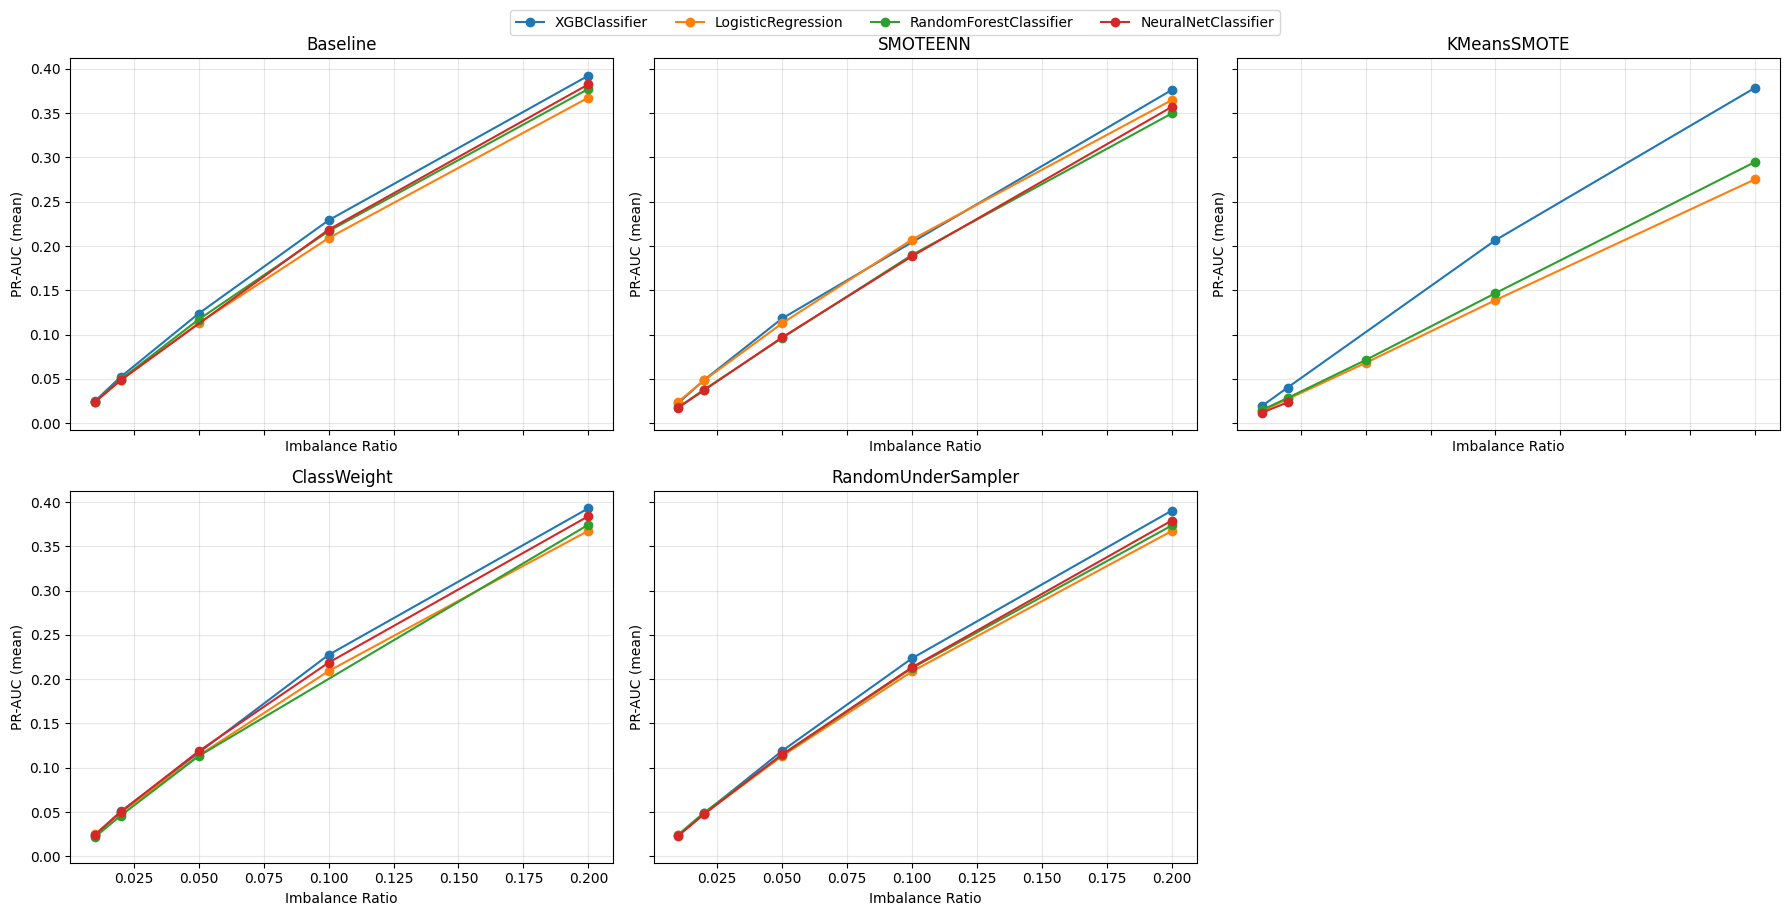

In [ ]:
ir_col   = "Imbalance ratio"
y_col    = "PR-AUC (mean)"

unique_samplers = model_results["Sampler"].unique()
models   = model_results["Model"].unique()

n = len(unique_samplers)
ncols = 3
nrows = -(-n // ncols) 

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.5 * nrows),
                         sharex=True, sharey=True)
axes = axes.flatten()

for ax, sampler in zip(axes, unique_samplers):
    sub = model_results[model_results["Sampler"] == sampler]
    for model in models:
        m = sub[sub["Model"] == model].sort_values(ir_col)
        if m.empty:
            continue
        ax.plot(m[ir_col], m[y_col], marker="o", label=model)

    ax.set_title(sampler)
    ax.set_xlabel("Imbalance Ratio")
    ax.set_ylabel(y_col)
    ax.grid(True, alpha=0.3)

for ax in axes[n:]:
    ax.set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center",
           ncol=len(models), bbox_to_anchor=(0.5, 1.02))

fig.tight_layout()
plt.show()


## 6.2 Global SHAP Analysis

Mean absolute SHAP values are collected inside each CV run using the last fold's already-fitted pipeline so no models are retrained. Results cover all combinations of model × sampler × imbalance ratio.


In [ ]:
shap_records_df = pd.read_csv("./shap_importances.csv")

In [ ]:
# Features treated as directly mutable in the constrained attacks
mutable_features = [
    "loan_amnt",
    "annual_inc",
    "revol_bal",
]

TOP_N = 15

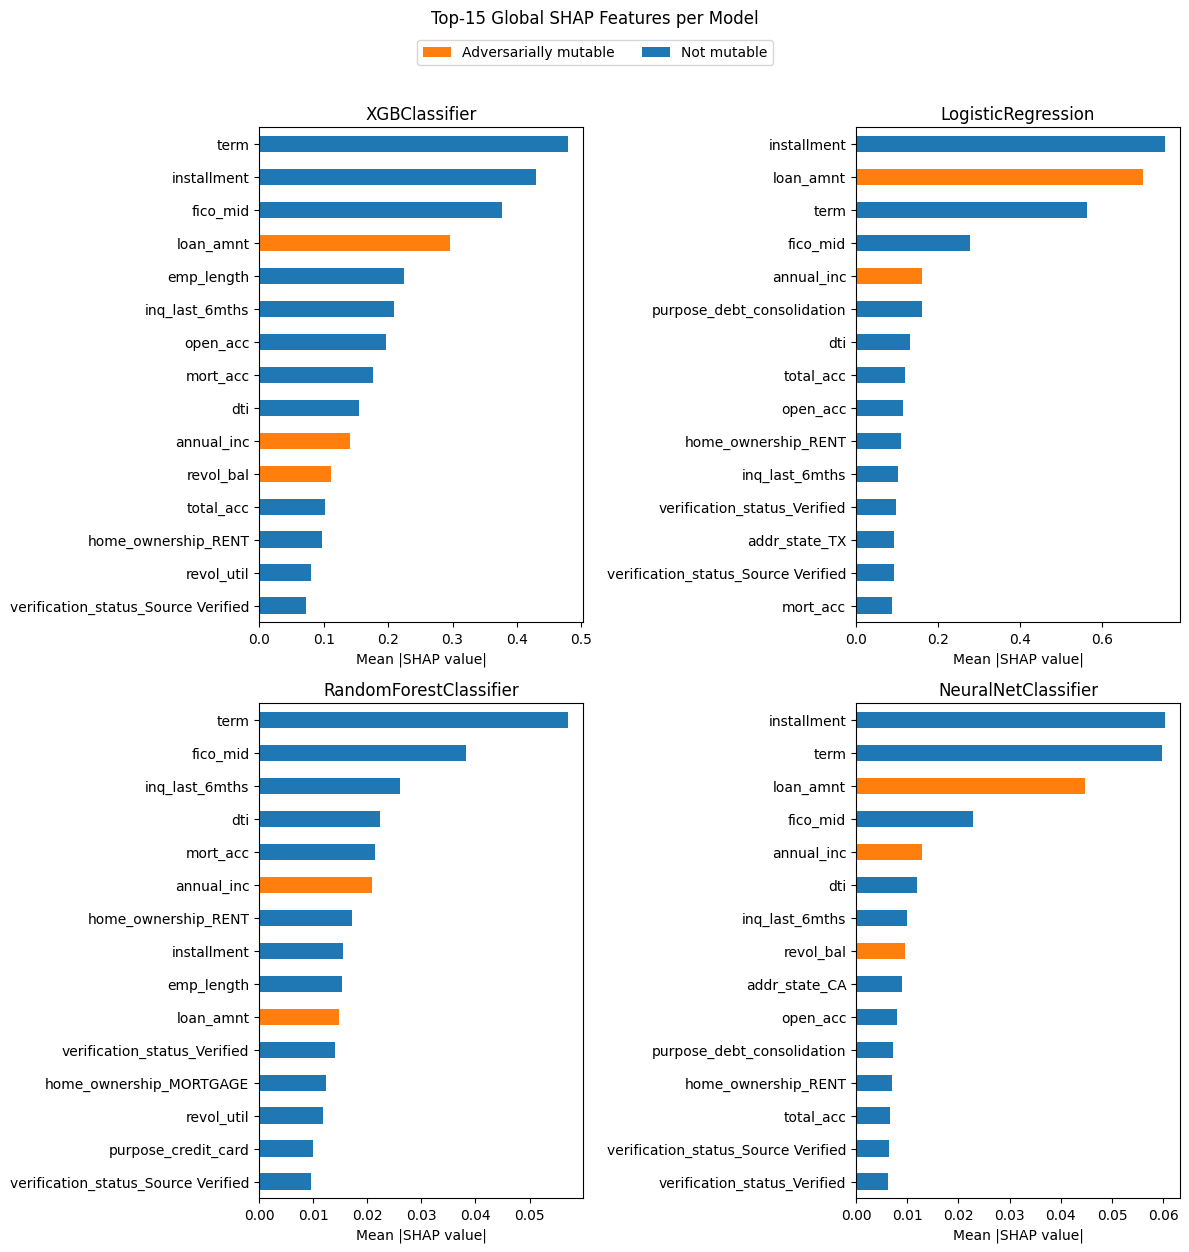

In [ ]:
def plot_shap(shap_wide: pd.DataFrame, outputs_dir: str, mutable_features: list, top_n: int = 15):
    feat_cols = [c for c in shap_wide.columns if c not in ("Model", "Sampler", "Imbalance ratio")]
    models_in_data = shap_wide["Model"].unique()

    n_models = len(models_in_data)
    ncols = 2
    nrows = math.ceil(n_models / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 6 * nrows))
    axes = np.atleast_1d(axes).flatten()

    for ax, model_name in zip(axes, models_in_data):
        imp = shap_wide[shap_wide["Model"] == model_name][feat_cols].mean().nlargest(top_n)
        colors = ["tab:orange" if f in mutable_features else "tab:blue" for f in imp.index]
        imp[::-1].plot(kind="barh", ax=ax, color=colors[::-1])
        ax.set_title(model_name)
        ax.set_xlabel("Mean |SHAP value|")

    # Hide any leftover empty subplots (e.g. 3 models in a 2x2 grid)
    for ax in axes[n_models:]:
        ax.set_visible(False)

    fig.legend(
        handles=[
            Patch(facecolor="tab:orange", label="Adversarially mutable"),
            Patch(facecolor="tab:blue",   label="Not mutable"),
        ],
        loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02),
    )
    fig.suptitle(f"Top-{top_n} Global SHAP Features per Model", y=1.04)
    plt.tight_layout()
    plt.show()

plot_shap(shap_records_df, outputs_dir=".", mutable_features=mutable_features, top_n=TOP_N)

# 7. Fairness / Disparate Impact Ratio (DIR)

This section evaluates whether the trained model gives the favourable prediction being classified as low-risk / non-default at different rates across groups defined by two features: employment length and annual income.

### What Disparate Impact Ratio measures

Disparate Impact Ratio (DIR) is a group fairness metric comparing the rate at which an unprivileged group receives a favourable outcome to the rate at which a privileged group does:

$$DIR = \frac{P(\hat{y}=1 \mid S = \text{unprivileged})}{P(\hat{y}=1 \mid S = \text{privileged})}$$

where $\hat{y}=1$ is the favourable prediction and $S$ is the group-defining attribute (here, `emp_length` or `annual_inc`) (Feldman et al., 2015). A DIR of 1.0 means both groups receive the favourable outcome at the same rate; values below 1 indicate the unprivileged group is disadvantaged, values above 1 indicate the privileged group is disadvantaged.

The metric traces back to U.S. employment discrimination law most notably *Griggs v. Duke Power Co.* and is operationalized in the EEOC's **four-fifths rule**: a selection rate ratio below 0.8 is treated as evidence of adverse impact requiring justification (Uniform Guidelines on Employee Selection Procedures; Feldman et al., 2015). In practice this 0.8 cutoff is often symmetrized to a 0.8–1.25 acceptable band, so that disadvantage to either group is flagged rather than only disadvantage to the unprivileged group (Varshney, 2022).

### Our two demographics

- **`emp_length`** — shorter employment history (unprivileged) vs. longer employment history (privileged).
- **`annual_inc`** — lower income (unprivileged) vs. higher income (privileged).

Both are continuous features that we binarize into privileged/unprivileged groups; the binarization threshold is itself a modeling choice that affects the resulting DIR value, so it's worth stating explicitly what threshold (e.g. a median split, or a fixed cutoff) is used and why, rather than leaving it implicit in the code.

**Neither `emp_length` nor `annual_inc` is a protected attribute** (unlike race, sex, or age) but in most financial dataset these demographics are present. In that case this methodology still holds. This analysis is better framed as checking for *proxy* disparities whether the model treats economically disadvantaged applicants differently.

### Why we fit the threshold on train, apply on test

As with the classification threshold in `score_model`, the decision threshold used to turn predicted probabilities into a favourable/unfavourable outcome is selected on the training split and only applied to the test split. This keeps the fairness evaluation itself free of test-set leakage. The concern isn't just inflated accuracy here, but an inflated (or deflated) DIR that doesn't reflect the model's genuine behaviour on unseen applicants.

In their paper, van Braak et al. (2025) discuss that DIR should be applied after resampling; therefore, it comes after the model implementation and evaluation in this notebook.

### Connecting this back to the project

This ties directly to our earlier finding that SMOTE-ENN produces disparate impact on `annual_inc`: rather than only observing that finding through the downstream fairness metric, reporting DIR per model, per resampling method, and per imbalance ratio lets us see *which* combinations of classifier and resampling strategy introduce or amplify group-level disparities, and whether that pattern holds consistently or is specific to particular models (e.g. tree ensembles vs. logistic regression) as imbalance increases.

## 7.1 set the configurations

In [ ]:
# target = 1 means default, so the favourable prediction is non-default.
FAVOURABLE_LABEL = 0

# For numerical features, use either:
# - method="threshold" with a fixed threshold, or
# - method="quantile" with a training-set quantile.
DIR_GROUP_SPECS = {
    "emp_length": {
        "method": "threshold",
        "threshold": 5,
        "unprivileged_if": "lower",   # lower than threshold = unprivileged
        "unprivileged_name": "emp_length < 5 years",
        "privileged_name": "emp_length >= 5 years",
    },
    "annual_inc": {
        "method": "quantile",
        "quantile": 0.50,             # median split based on the training set
        "unprivileged_if": "lower",
        "unprivileged_name": "lower annual income",
        "privileged_name": "higher annual income",
    },
}



### 7.2 Define helper functions

In [ ]:
def _get_group_threshold(feature, spec, X_reference):
    if spec["method"] == "threshold":
        return spec["threshold"]
    if spec["method"] == "quantile":
        return X_reference[feature].quantile(spec.get("quantile", 0.50))

#Return privileged/unprivileged group labels for one feature.
def make_binary_groups(feature, values, spec, threshold):
    if spec.get("unprivileged_if", "lower") == "lower":
        unprivileged_mask = values < threshold
    elif spec.get("unprivileged_if") == "higher":
        unprivileged_mask = values >= threshold

    return pd.Series(
        np.where(unprivileged_mask, spec["unprivileged_name"], spec["privileged_name"]),
        index=values.index,
        name=feature,
    )


def evaluate_dir_for_groups(
    y_true,
    y_pred,
    X_eval,
    X_reference,
    group_specs=DIR_GROUP_SPECS,
    favourable_label=FAVOURABLE_LABEL,
):
    y_true = pd.Series(np.asarray(y_true), index=X_eval.index, name="y_true")
    y_pred = pd.Series(np.asarray(y_pred), index=X_eval.index, name="y_pred")
    favourable_pred = (y_pred == favourable_label).astype(int)

    rows = []
    for feature, spec in group_specs.items():
        if feature not in X_eval.columns:
            print(f"Skipping {feature}: not found in X_eval")
            continue

        threshold = _get_group_threshold(feature, spec, X_reference)
        groups = make_binary_groups(feature, X_eval[feature], spec, threshold)

        tmp = pd.DataFrame({
            "group": groups,
            "y_true": y_true,
            "y_pred": y_pred,
            "favourable_pred": favourable_pred,
        })

        group_table = tmp.groupby("group").apply(
            lambda g: pd.Series({
                "n_samples": len(g),
                "favourable_prediction_rate": g["favourable_pred"].mean(),
                "default_prediction_rate": (g["y_pred"] == 1).mean(),
                "accuracy": accuracy_score(g["y_true"], g["y_pred"]),
            })
        )

        unpriv = spec["unprivileged_name"]
        priv = spec["privileged_name"]

        # Avoid divide-by-zero when the privileged group has no favourable predictions.
        priv_rate = group_table.loc[priv, "favourable_prediction_rate"] if priv in group_table.index else np.nan
        unpriv_rate = group_table.loc[unpriv, "favourable_prediction_rate"] if unpriv in group_table.index else np.nan
        dir_score = unpriv_rate / priv_rate if pd.notna(priv_rate) and priv_rate > 0 else np.nan

        for group_name, vals in group_table.iterrows():
            rows.append({
                "Feature": feature,
                "Group": group_name,
                "Role": "unprivileged" if group_name == unpriv else "privileged",
                "Threshold used": threshold,
                "DIR": dir_score,
                **vals.to_dict(),
            })

    return pd.DataFrame(rows)


### 7.3 Implementation of DIR

In [ ]:
# Run DIR evaluation for each imbalance ratio, sampler, and selected model.
# To save time, start with XGBoost only. Add other models here when needed.

xgb_params = config.get("XGBClassifier", {}).copy() if "config" in globals() else {}
xgb_params.setdefault("random_state", RANDOM_STATE)
xgb_params.setdefault("eval_metric", "logloss")

FAIRNESS_MODELS = [
    XGBClassifier(**xgb_params),
    # LogisticRegression(**config["LogisticRegression"]),
    # RandomForestClassifier(**config["RandomForestClassifier"]),
    # net_clf,
]

fairness_rows = []

for frac, (X_full, y_full) in datasets.items():
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_full,
        y_full,
        test_size=0.2,
        stratify=y_full,
        random_state=RANDOM_STATE,
    )

    for model in FAIRNESS_MODELS:
        model_name = model.__class__.__name__
        is_nn = model_name == "NeuralNetClassifier"
        y_fit = y_tr.to_numpy().astype(np.int64) if is_nn else y_tr

        for sampler_name, sampler in samplers.items():
            print(f"DIR evaluation: imbalance={frac}, model={model_name}, sampler={sampler_name}")

            try:
                est = apply_class_weight(clone(model), sampler_name, y_fit)
                pipe = build_pipeline(est, sampler)
                pipe.fit(X_tr, y_fit)

                y_pred = pipe.predict(X_te)

                fairness_results_df = evaluate_dir_for_groups(
                    y_true=y_te,
                    y_pred=y_pred,
                    X_eval=X_te,
                    X_reference=X_tr,
                    group_specs=DIR_GROUP_SPECS,
                    favourable_label=FAVOURABLE_LABEL,
                )

                fairness_results_df.insert(0, "Imbalance ratio", frac)
                fairness_results_df.insert(1, "Model", model_name)
                fairness_results_df.insert(2, "Sampler", sampler_name)
                fairness_rows.append(fairness_results_df)

            except Exception as e:
                fairness_rows.append(pd.DataFrame([{
                    "Imbalance ratio": frac,
                    "Model": model_name,
                    "Sampler": sampler_name,
                    "Feature": np.nan,
                    "Group": np.nan,
                    "Role": np.nan,
                    "Threshold used": np.nan,
                    "DIR": np.nan,
                    "n_samples": np.nan,
                    "favourable_prediction_rate": np.nan,
                    "default_prediction_rate": np.nan,
                    "accuracy": np.nan,
                    "Error": str(e),
                }]))
                print(f"FAILED: imbalance={frac}, model={model_name}, sampler={sampler_name}: {e}")

fairness_results_df = pd.concat(fairness_rows, ignore_index=True)
fairness_results_df.to_csv("dir_fairness_results.csv", index=False)
fairness_results_df.round(3)


In [ ]:
fairness_results_df = pd.read_csv("dir_fairness_results.csv")

### 7.4 Visualisation & Analysis

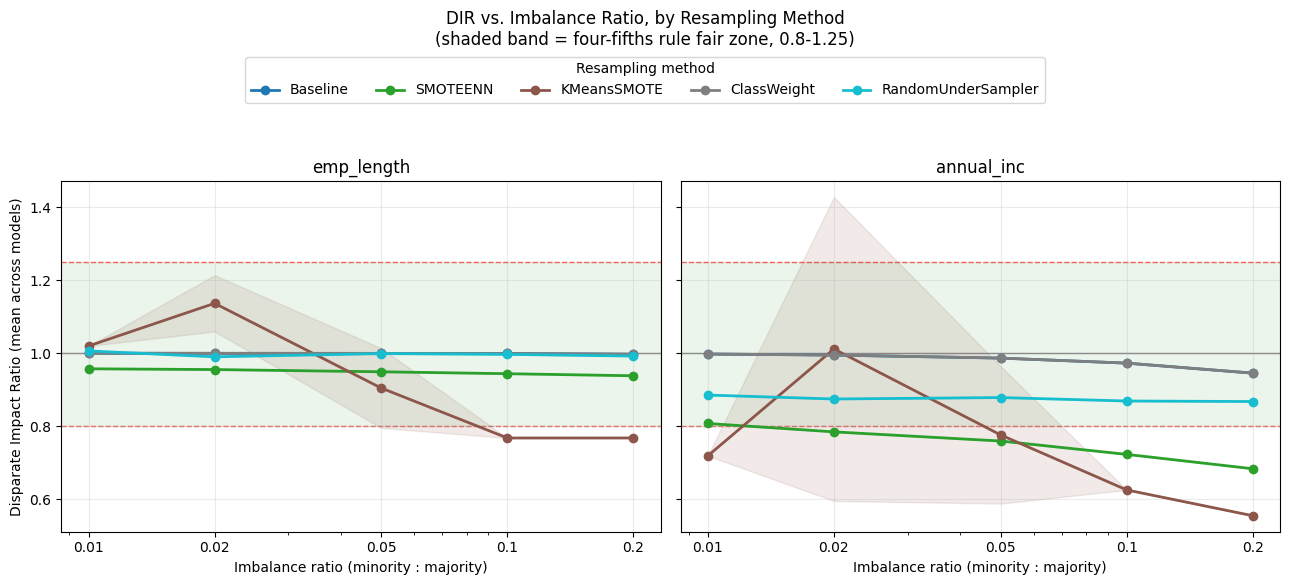

In [ ]:
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_samplers)))
sampler_colors = dict(zip(unique_samplers, colors))

fig1, axes1 = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
 
for ax, feature in zip(axes1, list(DIR_GROUP_SPECS.keys())):
    sub = fairness_results_df[fairness_results_df["Feature"] == feature]
    ax.axhspan(0.8, 1.25, color="green", alpha=0.08, zorder=0)
    ax.axhline(1.0, color="grey", linestyle="-", linewidth=1, zorder=1)
    ax.axhline(0.8, color="red", linestyle="--", linewidth=1, alpha=0.6, zorder=1)
    ax.axhline(1.25, color="red", linestyle="--", linewidth=1, alpha=0.6, zorder=1)
 
    for sampler in unique_samplers:
        s = sub[sub["Sampler"] == sampler].groupby("Imbalance ratio")["DIR"]
        mean = s.mean()
        std = s.std()
        ax.plot(mean.index, mean.values, marker="o", label=sampler,
                 color=sampler_colors[sampler], linewidth=2)
        ax.fill_between(mean.index, mean - std, mean + std,
                          color=sampler_colors[sampler], alpha=0.12)
 
    ax.set_title(feature)
    ax.set_xlabel("Imbalance ratio (minority : majority)")
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:g}"))
    ax.set_xticks(sorted(fairness_results_df["Imbalance ratio"].unique()))
    ax.grid(alpha=0.25)
 
axes1[0].set_ylabel("Disparate Impact Ratio (mean across models)")
handles, labels = axes1[0].get_legend_handles_labels()
fig1.legend(handles, labels, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.08),
            title="Resampling method")
fig1.suptitle("DIR vs. Imbalance Ratio, by Resampling Method\n(shaded band = four-fifths rule fair zone, 0.8-1.25)",
              y=1.16, fontsize=12)
fig1.tight_layout()
plt.show()


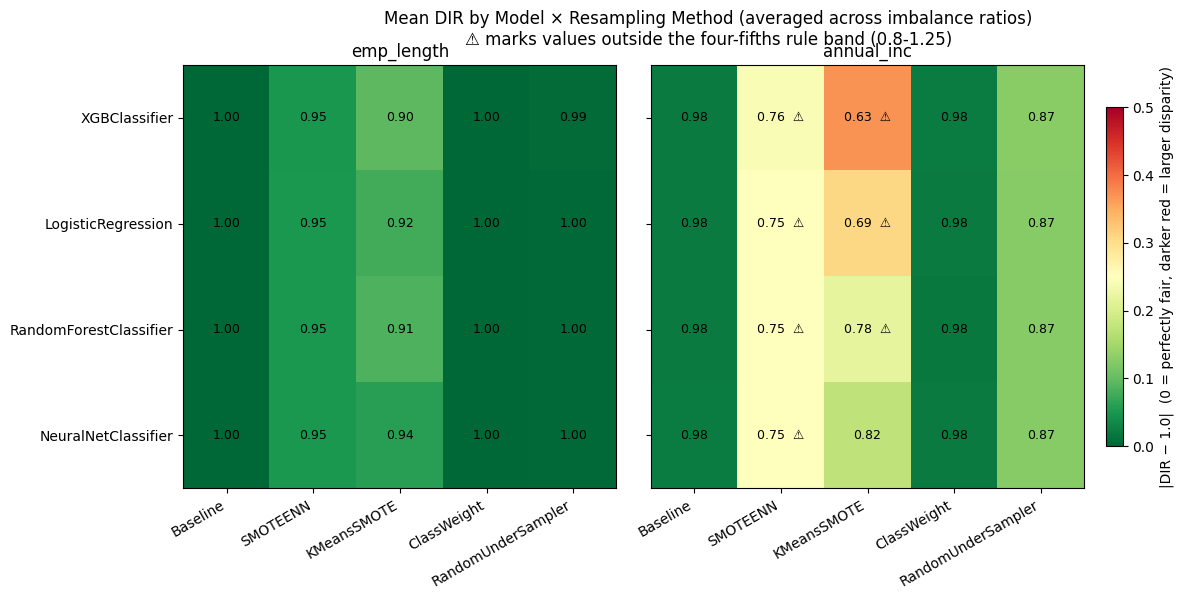

In [ ]:
fig2, axes2 = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
fig2.subplots_adjust(wspace=0.08)
 
for idx, (ax, feature) in enumerate(zip(axes2, list(DIR_GROUP_SPECS.keys()))):
    sub = fairness_results_df[fairness_results_df["Feature"] == feature]
    pivot = (
        sub.pivot_table(index="Model", columns="Sampler", values="DIR", aggfunc="mean")
           .reindex(index=models, columns=unique_samplers)
    )
    im = ax.imshow(pivot.values, cmap="RdYlGn_r", vmin=0.5, vmax=1.5, aspect="auto")
 
    dist = np.abs(pivot.values - 1.0)
    im = ax.imshow(dist, cmap="RdYlGn_r", vmin=0, vmax=0.5, aspect="auto")
 
    ax.set_xticks(range(len(unique_samplers)))
    ax.set_xticklabels(unique_samplers, rotation=30, ha="right")
    ax.set_yticks(range(len(models)))
    if idx == 0:
        ax.set_yticklabels(models)
    else:
        ax.tick_params(labelleft=False)
    ax.set_title(feature)
 
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            val = pivot.values[i, j]
            flag = "  \u26A0" if (val < 0.8 or val > 1.25) else ""
            ax.text(j, i, f"{val:.2f}{flag}", ha="center", va="center",
                     fontsize=9, color="black")
 
cbar = fig2.colorbar(im, ax=axes2, shrink=0.8, pad=0.02)
cbar.set_label("|DIR − 1.0|  (0 = perfectly fair, darker red = larger disparity)")
fig2.suptitle("Mean DIR by Model × Resampling Method (averaged across imbalance ratios)\n"
              "\u26A0 marks values outside the four-fifths rule band (0.8-1.25)", fontsize=12)
plt.show()

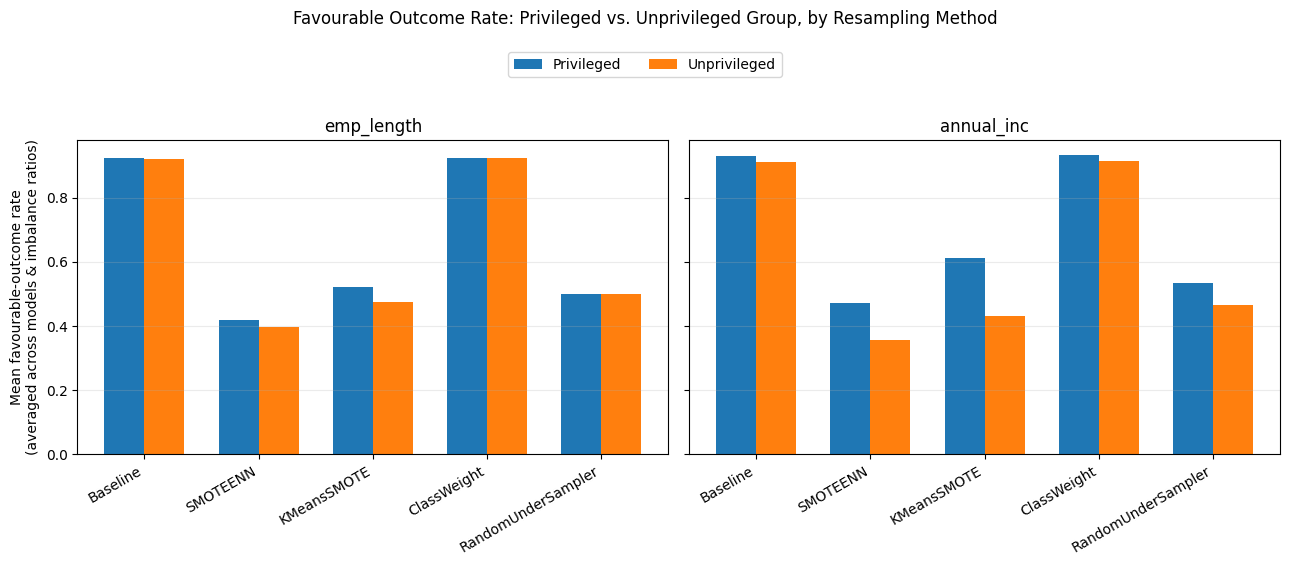

In [ ]:
rate_df = fairness_results_df.copy()
fig3, axes3 = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
width = 0.35
 
for ax, feature in zip(axes3, list(DIR_GROUP_SPECS.keys())):
    sub = rate_df[rate_df["Feature"] == feature]
    grp = sub.groupby(["Sampler", "Role"])["favourable_label_rate"].mean().unstack("Role")
    grp = grp.reindex(unique_samplers)
 
    x = np.arange(len(unique_samplers))
    ax.bar(x - width/2, grp["privileged"], width, label="Privileged", color="tab:blue")
    ax.bar(x + width/2, grp["unprivileged"], width, label="Unprivileged", color="tab:orange")
 
    ax.set_xticks(x)
    ax.set_xticklabels(unique_samplers, rotation=30, ha="right")
    ax.set_title(feature)
    ax.grid(axis="y", alpha=0.25)
 
axes3[0].set_ylabel("Mean favourable-outcome rate\n(averaged across models & imbalance ratios)")
handles, labels = axes3[0].get_legend_handles_labels()
fig3.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.05))
fig3.suptitle("Favourable Outcome Rate: Privileged vs. Unprivileged Group, by Resampling Method", y=1.12)
fig3.tight_layout()
plt.show()

# 8. Constrained Adversarial Attacks

This section evaluates constrained black-box attacks across model, resampling, and imbalance-ratio configurations, testing whether an actual defaulter could perturb a small set of realistically changeable application details to evade detection. Both attacks are *black-box*: they only require the model's output score (predicted probability of default), not access to its parameters, architecture, or analytical gradients which is an important property here, since two of our four models (random forrest and XGBoost) don't expose gradients in the way the neural network does, so any attack method needs to work identically across all four.

### The two attacks

**1. PermuteAttack-inspired genetic search.** PermuteAttack was originally proposed by Hashemi & Fathi (2020) specifically for credit scorecards which is roughly the same application domain as this project as a way to generate counterfactual examples for tabular data containing discrete and categorical variables, where gradient-based attacks (built for continuous, unconstrained image pixels) tend to produce unrealistic, out-of-distribution samples. It uses a gradient-free genetic algorithm: a population of candidate perturbations is evolved generation-over-generation, favouring candidates that flip the model's decision while keeping the number and magnitude of changed features small. Because it never needs a gradient, it applies unmodified to any classifier which is precisely why it's one of the two attacks chosen here rather than a gradient-based method that would only work on the neural network.

**2. ZOO-inspired finite-difference attack.** ZOO (Zeroth Order Optimization) was proposed by Chen et al. (2017) as a black-box attack for deep neural networks. Rather than using true backpropagated gradients, it estimates the gradient of the model's output at a point coordinate-by-coordinate using a symmetric finite-difference approximation by querying the model at $x + h e_i$ and $x - h e_i$ for a small step $h$ along each feature direction $e_i$, then using $\frac{f(x+he_i) - f(x-he_i)}{2h}$ as a stand-in for the true partial derivative. This "pseudo-gradient" is then used to guide the perturbation the same way a real gradient would in a white-box attack. ZOO was originally built for images (with thousands of pixels to estimate gradients over, making it query-expensive); applied here to tabular credit data with only a handful of mutable features, the finite-difference estimation is comparatively cheap, since only as many query pairs are needed as there are mutable features.

Together, these two represent different search philosophies a population-based genetic search vs. local gradient-estimate-guided search so agreement or disagreement between them is itself informative: if both attacks find similar vulnerabilities in a given (model, sampler, imbalance ratio) configuration, that's stronger evidence of a real weakness than either attack alone.

### Constraining the attack to feasible interventions

Only `loan_amnt`, `annual_inc`, and `revol_bal` are treated as directly mutable i.e., values an applicant could plausibly and directly alter (requesting a different loan amount, reporting different income, changing revolving balance by paying it down). This follows the actionable-recourse literature's distinction between features that are directly actionable, features that are mutable only as a *consequence* of a change to another feature, and features that are immutable entirely. Everything else that depends functionally on these three `installment`, debt-to-income ratio, and revolving utilization is recalculated after each intervention rather than left stale or independently perturbed. This matters for realism: if `loan_amnt` changes but `installment` isn't recomputed to match, the resulting "adversarial example" is an internally inconsistent data point that could never occur in practice, which would overstate how vulnerable the model actually is. Hashemi & Fathi (2020) apply an equivalent post-processing step in the original PermuteAttack paper specifically to preserve these higher-order conditional feature relationships, so this design choice is consistent with the source method rather than an ad hoc addition.

### Why only correctly-classified true defaults

Attacks are evaluated exclusively on held-out samples that (a) are true defaults and (b) the original (unattacked) model already correctly classifies as defaults. This defines the threat model precisely: we are asking whether a genuine bad-faith actor, someone who will in fact default, can perturb their application to slip past a model that would otherwise have caught them. This is the realistic, high-stakes adversarial scenario for a lender (evading correct rejection), as opposed to attacking already-misclassified points (which tells you nothing new) or attacking non-defaulters (whose "attack" would just be tightening their own true, favourable case).

## 8.1 define constants

In [ ]:
RANDOM_STATE = 42
DEFAULT_CLASS = 1

N_ATTACK_CASES = 100

# This is meaningful because there are three mutable features.
MAX_CHANGED_ACTIONS = 2

ACTION_SPECS = {
    "loan_amnt": {
        "direction": "decrease",
        "max_change": 0.25,
    },
    "annual_inc": {
        "direction": "increase",
        "max_change": 0.10,
    },
    "revol_bal": {
        "direction": "decrease",
        "max_change": 0.25,
    },
}

LOG_FEATURES = {
    "annual_inc",
    "revol_bal",
}

LOWER_Q = 0.01
UPPER_Q = 0.99

GA_POP_SIZE = 50
GA_GENERATIONS = 100
GA_RESTARTS = 5
GA_MUTATION_PROB = 0.20
GA_MUTATION_SCALE = 0.15
GA_ELITE_FRAC = 0.20

ZOO_MAX_ITER = 200
ZOO_RESTARTS = 3
ZOO_LEARNING_RATE = 0.03
ZOO_FD_STEP = 0.05

PROXIMITY_PENALTY = 0.02

## 8.2 Define Helper functions and metrics

In [ ]:
def to_raw(value, feature):
    value = float(value)
    return max(np.expm1(value), 0.0) if feature in LOG_FEATURES else value


def to_model(value, feature):
    value = max(float(value), 0.0)
    return np.log1p(value) if feature in LOG_FEATURES else value


def get_action_features(columns):
    return [feature for feature in ACTION_SPECS if feature in columns]


def project_action_vector(z):
    z = np.clip(np.asarray(z, dtype=float), 0.0, 1.0)

    active = np.flatnonzero(z > 1e-12)

    if len(active) > MAX_CHANGED_ACTIONS:
        keep = active[np.argsort(z[active])[-MAX_CHANGED_ACTIONS:]]
        mask = np.zeros(len(z), dtype=bool)
        mask[keep] = True
        z = np.where(mask, z, 0.0)

    return z


def get_bounds(x_original, X_reference, action_features):
    bounds = {}

    for feature in action_features:
        original = to_raw(x_original.iloc[0][feature], feature)

        values = X_reference[feature].astype(float).to_numpy()

        if feature in LOG_FEATURES:
            values = np.expm1(values)

        values = values[np.isfinite(values)]

        if len(values) == 0:
            bounds[feature] = (original, original)
            continue

        q_low = float(np.nanquantile(values, LOWER_Q))
        q_high = float(np.nanquantile(values, UPPER_Q))

        direction = ACTION_SPECS[feature]["direction"]
        max_change = ACTION_SPECS[feature]["max_change"]

        if direction == "increase":
            low = original
            high = min(original * (1 + max_change), q_high)

            if high < low:
                high = low

        elif direction == "decrease":
            low = max(original * (1 - max_change), q_low, 0.0)
            high = original

            if low > high:
                low = high

        bounds[feature] = (float(low), float(high))

    return bounds

In [ ]:
def repair_features(x_adv, x_original):
    eps = 1e-10

    if {"loan_amnt", "installment"}.issubset(x_adv.columns):
        old_loan = max(float(x_original.iloc[0]["loan_amnt"]), eps)
        old_installment = float(x_original.iloc[0]["installment"])
        new_loan = float(x_adv.iloc[0]["loan_amnt"])

        x_adv.loc[:, "installment"] = (
            old_installment * new_loan / old_loan
        )

    if {"annual_inc", "dti"}.issubset(x_adv.columns):
        old_income = max(
            to_raw(x_original.iloc[0]["annual_inc"], "annual_inc"),
            eps,
        )

        new_income = max(
            to_raw(x_adv.iloc[0]["annual_inc"], "annual_inc"),
            eps,
        )

        old_dti = float(x_original.iloc[0]["dti"])

        x_adv.loc[:, "dti"] = max(
            0.0,
            old_dti * old_income / new_income,
        )

    if {"revol_bal", "revol_util"}.issubset(x_adv.columns):
        old_balance = to_raw(
            x_original.iloc[0]["revol_bal"],
            "revol_bal",
        )

        old_util = float(x_original.iloc[0]["revol_util"])

        if old_balance > eps and old_util > eps:
            credit_limit = old_balance / (old_util / 100.0)

            new_balance = to_raw(
                x_adv.iloc[0]["revol_bal"],
                "revol_bal",
            )

            x_adv.loc[:, "revol_util"] = np.clip(
                100.0 * new_balance / credit_limit,
                0.0,
                100.0,
            )

    return x_adv


def vector_to_instance(z, x_original, bounds, action_features):
    z_effective = project_action_vector(z)

    x_adv = x_original.copy(deep=True)

    for i, feature in enumerate(action_features):
        original = to_raw(x_original.iloc[0][feature], feature)
        low, high = bounds[feature]

        if ACTION_SPECS[feature]["direction"] == "increase":
            new_value = original + z_effective[i] * (high - original)
        else:
            new_value = original - z_effective[i] * (original - low)

        new_value = np.clip(new_value, low, high)

        x_adv.loc[:, feature] = to_model(new_value, feature)

    x_adv = repair_features(x_adv, x_original)

    return x_adv, z_effective


def default_probability_index(model):
    classes = np.asarray(model.classes_)

    matches = np.where(classes == DEFAULT_CLASS)[0]

    if len(matches) != 1:
        raise ValueError(
            f"Default class {DEFAULT_CLASS} was not found in {classes}."
        )

    return int(matches[0])


def default_probabilities(model, X):
    class_index = default_probability_index(model)
    return model.predict_proba(X)[:, class_index]


def default_probability(model, X, query_counter=None):
    if query_counter is not None:
        query_counter["count"] += 1

    return float(default_probabilities(model, X)[0])


def get_threshold(model, X_validation, y_validation):
    probabilities = default_probabilities(model, X_validation)

    precision, recall, thresholds = precision_recall_curve(
        y_validation,
        probabilities,
        pos_label=DEFAULT_CLASS,
    )

    if len(thresholds) == 0:
        return 0.50

    f1_scores = (
        2.0
        * precision[:-1]
        * recall[:-1]
        / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    )

    return float(thresholds[np.argmax(f1_scores)])


def changed_features(x_adv, x_original, action_features):
    return int(
        sum(
            abs(
                to_raw(x_adv.iloc[0][feature], feature)
                - to_raw(x_original.iloc[0][feature], feature)
            ) > 1e-8
            for feature in action_features
        )
    )



In [ ]:
def evaluate_candidate(
    z,
    model,
    x_original,
    bounds,
    action_features,
    query_counter,
):
    x_adv, z_effective = vector_to_instance(
        z,
        x_original,
        bounds,
        action_features,
    )

    adversarial_probability = default_probability(
        model,
        x_adv,
        query_counter,
    )

    perturbation_cost = np.mean(np.abs(z_effective))

    score = (
        adversarial_probability
        + PROXIMITY_PENALTY * perturbation_cost
    )

    return score, adversarial_probability, x_adv, z_effective


def create_result(
    method,
    original_probability,
    adversarial_probability,
    x_original,
    x_adv,
    action_features,
    threshold,
    query_counter,
    runtime_seconds,
):
    result = {
        "Method": method,
        "Success": int(adversarial_probability < threshold),
        "Original default probability": original_probability,
        "Adversarial default probability": adversarial_probability,
        "Probability reduction": (
            original_probability - adversarial_probability
        ),
        "Changed features": changed_features(
            x_adv,
            x_original,
            action_features,
        ),
        "Queries": int(query_counter["count"]),
        "Runtime seconds": runtime_seconds,
    }

    for feature in action_features:
        before = to_raw(x_original.iloc[0][feature], feature)
        after = to_raw(x_adv.iloc[0][feature], feature)

        result[f"{feature}_before"] = before
        result[f"{feature}_after"] = after
        result[f"{feature}_relative_change"] = (
            (after - before) / before
            if before != 0
            else np.nan
        )

    return result

## 8.3 Define PermuteAttack

In [ ]:
def permute_attack(
    model,
    x_original,
    X_reference,
    action_features,
    threshold,
    seed=RANDOM_STATE,
):
    rng = np.random.default_rng(seed)

    start = time.perf_counter()
    query_counter = {"count": 0}

    bounds = get_bounds(
        x_original,
        X_reference,
        action_features,
    )

    original_probability = default_probability(
        model,
        x_original,
        query_counter,
    )

    d = len(action_features)

    best_score = np.inf
    best_probability = original_probability
    best_x_adv = x_original.copy(deep=True)

    n_elite = max(
        2,
        int(GA_POP_SIZE * GA_ELITE_FRAC),
    )

    for _ in range(GA_RESTARTS):
        population = rng.uniform(
            low=0.0,
            high=1.0,
            size=(GA_POP_SIZE, d),
        )

        population[0] = np.zeros(d)

        population = np.asarray(
            [project_action_vector(z) for z in population]
        )

        for _ in range(GA_GENERATIONS):
            evaluations = []

            for z in population:
                score, probability, x_adv, z_effective = evaluate_candidate(
                    z=z,
                    model=model,
                    x_original=x_original,
                    bounds=bounds,
                    action_features=action_features,
                    query_counter=query_counter,
                )

                evaluations.append(
                    {
                        "score": score,
                        "probability": probability,
                        "x_adv": x_adv,
                        "z": z_effective,
                    }
                )

            evaluations.sort(key=lambda item: item["score"])

            if evaluations[0]["score"] < best_score:
                best_score = evaluations[0]["score"]
                best_probability = evaluations[0]["probability"]
                best_x_adv = evaluations[0]["x_adv"].copy(deep=True)

            successful = [
                item
                for item in evaluations
                if item["probability"] < threshold
            ]

            if successful:
                selected = min(
                    successful,
                    key=lambda item: item["score"],
                )

                return create_result(
                    method="PermuteAttack-inspired GA",
                    original_probability=original_probability,
                    adversarial_probability=selected["probability"],
                    x_original=x_original,
                    x_adv=selected["x_adv"],
                    action_features=action_features,
                    threshold=threshold,
                    query_counter=query_counter,
                    runtime_seconds=time.perf_counter() - start,
                )

            elites = np.asarray(
                [
                    item["z"]
                    for item in evaluations[:n_elite]
                ]
            )

            children = [elite.copy() for elite in elites]

            while len(children) < GA_POP_SIZE:
                parent_1 = elites[
                    rng.integers(0, len(elites))
                ]

                parent_2 = elites[
                    rng.integers(0, len(elites))
                ]

                crossover_mask = rng.random(d) < 0.5

                child = np.where(
                    crossover_mask,
                    parent_1,
                    parent_2,
                )

                mutation_mask = rng.random(d) < GA_MUTATION_PROB

                child[mutation_mask] += rng.normal(
                    loc=0.0,
                    scale=GA_MUTATION_SCALE,
                    size=mutation_mask.sum(),
                )

                if rng.random() < 0.30:
                    child[rng.integers(0, d)] = 0.0

                children.append(
                    project_action_vector(child)
                )

            population = np.asarray(children)

    return create_result(
        method="PermuteAttack-inspired GA",
        original_probability=original_probability,
        adversarial_probability=best_probability,
        x_original=x_original,
        x_adv=best_x_adv,
        action_features=action_features,
        threshold=threshold,
        query_counter=query_counter,
        runtime_seconds=time.perf_counter() - start,
    )

## 8.4 Define ZOO

In [ ]:
def zoo_attack(
    model,
    x_original,
    X_reference,
    action_features,
    threshold,
    seed=RANDOM_STATE
):
    rng = np.random.default_rng(seed)

    start = time.perf_counter()
    query_counter = {"count": 0}

    bounds = get_bounds(
        x_original,
        X_reference,
        action_features,
    )

    original_probability = default_probability(
        model,
        x_original,
        query_counter,
    )

    d = len(action_features)

    best_score = np.inf
    best_probability = original_probability
    best_x_adv = x_original.copy(deep=True)

    for restart in range(ZOO_RESTARTS):
        if restart == 0:
            z = np.zeros(d)
        else:
            z = rng.uniform(
                low=0.0,
                high=0.25,
                size=d,
            )

        z = project_action_vector(z)

        m = np.zeros(d)
        v = np.zeros(d)

        current_score, current_probability, current_x_adv, z = (
            evaluate_candidate(
                z=z,
                model=model,
                x_original=x_original,
                bounds=bounds,
                action_features=action_features,
                query_counter=query_counter,
            )
        )

        if current_score < best_score:
            best_score = current_score
            best_probability = current_probability
            best_x_adv = current_x_adv.copy(deep=True)

        for iteration in range(1, ZOO_MAX_ITER + 1):
            gradient = np.zeros(d)

            for j in range(d):
                z_plus = z.copy()
                z_minus = z.copy()

                z_plus[j] = min(
                    1.0,
                    z_plus[j] + ZOO_FD_STEP,
                )

                z_minus[j] = max(
                    0.0,
                    z_minus[j] - ZOO_FD_STEP,
                )

                f_plus, _, _, _ = evaluate_candidate(
                    z=z_plus,
                    model=model,
                    x_original=x_original,
                    bounds=bounds,
                    action_features=action_features,
                    query_counter=query_counter,
                )

                f_minus, _, _, _ = evaluate_candidate(
                    z=z_minus,
                    model=model,
                    x_original=x_original,
                    bounds=bounds,
                    action_features=action_features,
                    query_counter=query_counter,
                )

                denominator = max(
                    z_plus[j] - z_minus[j],
                    1e-8,
                )

                gradient[j] = (
                    f_plus - f_minus
                ) / denominator

            beta_1 = 0.90
            beta_2 = 0.999

            m = beta_1 * m + (1.0 - beta_1) * gradient
            v = beta_2 * v + (1.0 - beta_2) * gradient**2

            m_hat = m / (1.0 - beta_1**iteration)
            v_hat = v / (1.0 - beta_2**iteration)

            proposal = z - ZOO_LEARNING_RATE * m_hat / (
                np.sqrt(v_hat) + 1e-8
            )

            proposal = project_action_vector(proposal)

            (
                proposal_score,
                proposal_probability,
                proposal_x_adv,
                proposal_z,
            ) = evaluate_candidate(
                z=proposal,
                model=model,
                x_original=x_original,
                bounds=bounds,
                action_features=action_features,
                query_counter=query_counter,
            )

            if proposal_score <= current_score:
                z = proposal_z
                current_score = proposal_score
                current_probability = proposal_probability
                current_x_adv = proposal_x_adv

            if current_score < best_score:
                best_score = current_score
                best_probability = current_probability
                best_x_adv = current_x_adv.copy(deep=True)

            if current_probability < threshold:
                return create_result(
                    method="ZOO-inspired finite difference",
                    original_probability=original_probability,
                    adversarial_probability=current_probability,
                    x_original=x_original,
                    x_adv=current_x_adv,
                    action_features=action_features,
                    threshold=threshold,
                    query_counter=query_counter,
                    runtime_seconds=time.perf_counter() - start,
                )

    return create_result(
        method="ZOO-inspired finite difference",
        original_probability=original_probability,
        adversarial_probability=best_probability,
        x_original=x_original,
        x_adv=best_x_adv,
        action_features=action_features,
        threshold=threshold,
        query_counter=query_counter,
        runtime_seconds=time.perf_counter() - start,
    )

## 8.5 Implement Attacks

In [ ]:
xgb_attack_params = config["XGBClassifier"].copy()
xgb_attack_params["random_state"] = RANDOM_STATE
xgb_attack_params["eval_metric"] = "logloss"

lr_attack_params = config["LogisticRegression"].copy()
lr_attack_params["random_state"] = RANDOM_STATE

rf_attack_params = config["RandomForestClassifier"].copy()
rf_attack_params["random_state"] = RANDOM_STATE
rf_attack_params["n_jobs"] = -1

ATTACK_MODELS = [
    XGBClassifier(**xgb_attack_params),
    LogisticRegression(**lr_attack_params),
    RandomForestClassifier(**rf_attack_params),
    net_clf,
]

attack_results = []
attack_errors = []

required_attack_columns = [
    "loan_amnt",
    "annual_inc",
    "revol_bal",
    "installment",
    "dti",
    "revol_util",
]

configuration_number = 0

In [ ]:
for fraction, (X_full, y_full) in datasets.items():
    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X_full,
        y_full,
        test_size=0.20,
        stratify=y_full,
        random_state=RANDOM_STATE,
    )

    X_train, X_validation, y_train, y_validation = train_test_split(
        X_train_val,
        y_train_val,
        test_size=0.20,
        stratify=y_train_val,
        random_state=RANDOM_STATE,
    )

    action_features = get_action_features(X_train.columns)

    if len(action_features) != len(ACTION_SPECS):
        raise ValueError(
            "One or more configured action features are missing."
        )

    available_required_columns = [
        column
        for column in required_attack_columns
        if column in X_test.columns
    ]

    for base_model in ATTACK_MODELS:
        model_name = base_model.__class__.__name__

        for sampler_name, sampler in samplers.items():
            configuration_number += 1

            print(
                f"Running: ratio={fraction}, "
                f"model={model_name}, "
                f"sampler={sampler_name}"
            )

            try:
                y_fit = y_train.to_numpy().astype(np.int64)

                estimator = apply_class_weight(
                    clone(base_model),
                    sampler_name,
                    y_fit,
                )

                sampler_instance = (
                    clone(sampler)
                    if sampler is not None
                    else None
                )

                pipeline = build_pipeline(
                    estimator,
                    sampler_instance,
                )

                pipeline.fit(X_train, y_fit)

                threshold = get_threshold(
                    pipeline,
                    X_validation,
                    y_validation,
                )

                test_default_probabilities = default_probabilities(
                    pipeline,
                    X_test,
                )

                candidate_mask = (
                    (y_test.to_numpy() == DEFAULT_CLASS)
                    & (test_default_probabilities >= threshold)
                )

                if available_required_columns:
                    complete_mask = (
                        X_test[available_required_columns]
                        .notna()
                        .all(axis=1)
                        .to_numpy()
                    )

                    candidate_mask &= complete_mask

                candidates = X_test.loc[candidate_mask].copy()

                if len(candidates) == 0:
                    print("No eligible attack cases.")
                    continue

                candidates = candidates.sample(
                    n=min(N_ATTACK_CASES, len(candidates)),
                    random_state=RANDOM_STATE + configuration_number,
                )

                for case_number, (_, row) in enumerate(
                    candidates.iterrows()
                ):
                    x_original = row.to_frame().T
                    x_original = x_original.reindex(
                        columns=X_train.columns
                    )

                    case_seed = (
                        RANDOM_STATE
                        + 100000 * configuration_number
                        + case_number
                    )

                    ga_result = permute_attack(
                        model=pipeline,
                        x_original=x_original,
                        X_reference=X_train,
                        action_features=action_features,
                        threshold=threshold,
                        seed=case_seed,
                    )

                    ga_result.update(
                        {
                            "Imbalance ratio": fraction,
                            "Model": model_name,
                            "Sampler": sampler_name,
                            "Case": case_number,
                            "Threshold": threshold,
                        }
                    )

                    attack_results.append(ga_result)

                    zoo_result = zoo_attack(
                        model=pipeline,
                        x_original=x_original,
                        X_reference=X_train,
                        action_features=action_features,
                        threshold=threshold,
                        seed=case_seed + 50000,
                    )

                    zoo_result.update(
                        {
                            "Imbalance ratio": fraction,
                            "Model": model_name,
                            "Sampler": sampler_name,
                            "Case": case_number,
                            "Threshold": threshold,
                        }
                    )

                    attack_results.append(zoo_result)

            except Exception as error:
                attack_errors.append(
                    {
                        "Imbalance ratio": fraction,
                        "Model": model_name,
                        "Sampler": sampler_name,
                        "Error": str(error),
                    }
                )

                print(
                    f"FAILED: ratio={fraction}, "
                    f"model={model_name}, "
                    f"sampler={sampler_name}\n{error}"
                )

In [ ]:
attack_results = pd.DataFrame(attack_results)
attack_errors = pd.DataFrame(attack_errors)

if attack_results.empty:
    raise RuntimeError(
        "No attack results were produced. "
        "Inspect attack_errors for details."
    )

attack_summary = (
    attack_results
    .groupby(
        [
            "Imbalance ratio",
            "Model",
            "Sampler",
            "Method",
        ],
        as_index=False,
    )
    .agg(
        Attack_Success_Rate=("Success", "mean"),
        Mean_Probability_Reduction=(
            "Probability reduction",
            "mean",
        ),
        Mean_Changed_Features=(
            "Changed features",
            "mean",
        ),
        Median_Queries=("Queries", "median"),
        Median_Runtime_Seconds=(
            "Runtime seconds",
            "median",
        ),
        N_Attacked=("Success", "count"),
    )
)

display(attack_summary)

In [ ]:
if not attack_errors.empty:
    display(attack_errors)

attack_results.to_csv(
    "attack_results.csv",
    index=False,
)

attack_summary.to_csv(
    "attack_summary.csv",
    index=False,
)

attack_errors.to_csv(
    "attack_errors.csv",
    index=False,
)

## 8.7 Analyse attacks

In [ ]:
attack_results = pd.read_csv("adversarial_attack_results.csv")

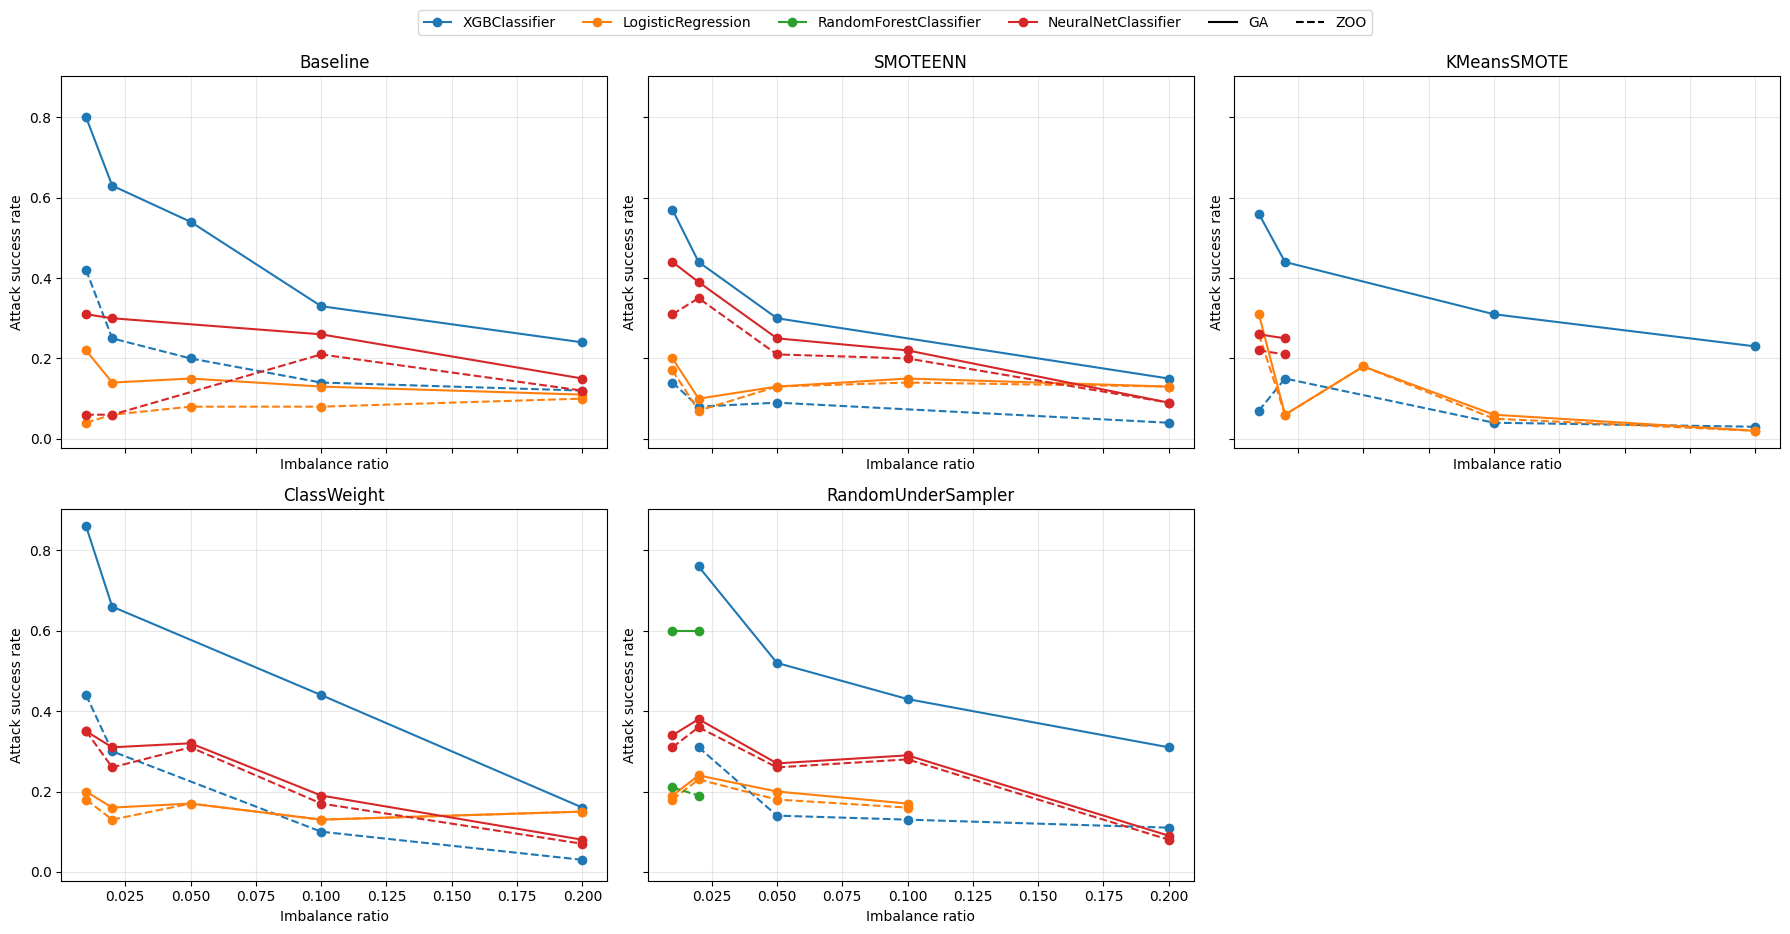

In [ ]:
def plot_attack_success(adf: pd.DataFrame, outputs_dir: str):
    ir_col = "Imbalance ratio"
    
    method_styles = [("GA", "-"), ("ZOO", "--")]
    methods = [
        (name, ls) for name, ls in method_styles
        if f"Attack success rate ({name})" in adf.columns
    ]
    if not methods:  
        methods = [("", "-")]

    samplers = adf["Sampler"].unique()
    models = list(adf["Model"].unique())
    color_cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    model_color = {m: color_cycle[i % len(color_cycle)] for i, m in enumerate(models)}

    n = len(samplers)
    ncols = 3
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.5 * nrows), sharex=True, sharey=True)
    axes = np.atleast_1d(axes).flatten()
    for ax, sampler in zip(axes, samplers):
        sub = adf[adf["Sampler"] == sampler]
        for model in models:
            m = sub[sub["Model"] == model].sort_values(ir_col)
            if m.empty:
                continue
            for name, ls in methods:
                col = f"Attack success rate ({name})" if name else "Attack success rate"
                if col in m:
                    ax.plot(m[ir_col], m[col], marker="o", linestyle=ls, color=model_color[model])
        ax.set_title(sampler)
        ax.set_xlabel("Imbalance ratio")
        ax.set_ylabel("Attack success rate")
        ax.grid(True, alpha=0.3)
    for ax in axes[n:]:
        ax.set_visible(False)

    
    from matplotlib.lines import Line2D
    model_handles = [Line2D([0], [0], color=model_color[m], marker="o", label=m) for m in models]
    method_handles = [
        Line2D([0], [0], color="black", linestyle=ls, label=name)
        for name, ls in methods if name
    ]
    handles = model_handles + method_handles
    fig.legend(handles, [h.get_label() for h in handles],
               loc="upper center", ncol=len(handles), bbox_to_anchor=(0.5, 1.04))
    fig.tight_layout()
    fig.savefig('./attack_success_rate.png', bbox_inches="tight", dpi=150)
    plt.show()

plot_attack_success(attack_results, outputs_dir=".")